In [1]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    x = torch.randn(3000, 3000, device=device)
    y = torch.matmul(x, x)
    torch.cuda.synchronize()
    del x, y
    torch.cuda.empty_cache()
    print("GPU computation successful!")
else:
    print("CUDA not available; running on CPU fallback.")

Training Device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU
GPU computation successful!


# Automated Pneumonia Detection from Chest X-Ray Images Using Deep Learning and Transfer Learning

**Authors & Affiliation**: Medical Imaging AI Research Group, Computational Medicine & Deep Learning Laboratory  
**Clinical Scope**: Pulmonary Triage, Emergency Department Chest Radiograph Screening, Computer-Aided Diagnosis (CAD)  
**Dataset Reference**: RSNA Pneumonia Detection Challenge / Processed Benchmark (`iamtapendu/rsna-pneumonia-processed-dataset`)

---

## 1. Executive Summary & Clinical Context

Pneumonia is an acute inflammatory infection of the pulmonary parenchyma affecting one or both lungs, primarily localized to the microscopic air sacs (alveoli). When an individual contracts pneumonia, the alveoli fill with pus, cellular debris, and inflammatory fluid (exudate), severely impairing gas exchange and causing dyspnea, fever, productive cough, and systemic hypoxemia. Globally, pneumonia remains the single largest infectious cause of mortality among pediatric populations under the age of five (accounting for over 700,000 deaths annually) and imposes an enormous clinical burden on elderly and immunocompromised adults.

### 1.1 The Role of Chest Radiographs (CXRs)
Chest radiography remains the primary first-line diagnostic imaging modality worldwide for pulmonary evaluation due to its ubiquitous availability, rapid acquisition time, cost-effectiveness, and low ionizing radiation dose relative to computed tomography (CT). On a standard anterior-posterior (AP) or posterior-anterior (PA) chest radiograph, normal lung parenchyma is radiolucent (appearing relatively dark) because air attenuates very few X-ray photons. Conversely, pneumonia manifests as areas of increased radiodensity (radio-opacity), representing consolidated airspaces, interstitial infiltration, or bronchial cuffing.

### 1.2 Key Diagnostic Challenges in Radiology
1. **Low Contrast & Subtle Infiltrates**: Early-stage bacterial or atypical viral pneumonias often present with faint, ill-defined opacities that blend into background vascular markings.
2. **Anatomical Superposition**: Planar 2D projection compresses 3D anatomical structures. The cardiac silhouette, rib cage, clavicles, pulmonary vessels, and diaphragm overlap lung zones, creating diagnostic blind spots (e.g., retrocardiac and retrodiaphragmatic opacities).
3. **Inter-Observer & Intra-Observer Variability**: Diagnostic concordance among experienced radiologists for pneumonia screening on CXRs typically ranges between 65% and 80%, compounded by diagnostic fatigue in emergency triage.
4. **Scarcity of Radiologists**: In rural, remote, and developing regions, the ratio of radiologists to patients is critically low, resulting in dangerous diagnostic delays.

### 1.3 Project Objectives & Machine Learning Pipeline
This project establishes a standardized, reproducible, end-to-end deep learning framework to automatically identify and classify pneumonia from chest radiographs. Specifically, this study implements, trains, and empirically compares five distinct architectures:
- **Model A**: A Custom Deep Convolutional Neural Network (CNN) built from first principles with batch normalization and spatial dropout.
- **Model B**: VGG16 (Simonyan & Zisserman) using transfer learning with a two-stage fine-tuning schedule.
- **Model C**: ResNet50 (He et al.) utilizing deep residual skip connections.
- **Model D**: MobileNetV2 (Sandler et al.) leveraging inverted residuals and linear bottlenecks for edge/point-of-care deployment.
- **Model E**: EfficientNetB0 (Tan & Le) applying compound coefficient scaling balancing depth, width, and resolution.

---

> [!WARNING] **High-Priority Regulatory & Medical AI Safety Warning**
> This notebook, the associated codebase, and the trained neural network models are developed strictly for **academic research, scientific evaluation, and technical benchmarking purposes only**.
> - This system is **NOT** a certified medical device cleared or approved by the US FDA, European CE, or any regulatory health agency.
> - This model must **NEVER** be used as a standalone diagnostic instrument, autonomous triage agent, or primary basis for therapeutic, surgical, or clinical decision-making.
> - Clinical management of suspected pneumonia must always integrate comprehensive clinical history, physical examination (auscultation), vital signs, microbiological laboratory findings, and oversight by a board-certified physician or radiologist.

---
## 2. Environment Setup, Diagnostics & Hardware Acceleration

In this section, we initialize the computational workspace, import necessary scientific and deep learning libraries, configure deterministic random seeds to ensure rigorous reproducibility across experiments, and configure native **PyTorch CUDA GPU acceleration** with Automatic Mixed Precision (AMP).

Because native Windows TensorFlow ($\ge 2.11$) executes CPU-only without CUDA support, running all five convolutional architectures on PyTorch CUDA provides dramatic training speedups on NVIDIA GPUs while maintaining full scientific parity across architectures, optimization schedules, evaluation metrics, and Grad-CAM interpretability.

In [2]:
import os
import sys
import gc
import time
import json
import copy
import random
import warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

warnings.filterwarnings("ignore")

# Numerical, data manipulation, and visualization libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
import cv2

ImageFile.LOAD_TRUNCATED_IMAGES = True

# Machine learning utilities and statistical evaluation
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, matthews_corrcoef,
    cohen_kappa_score, balanced_accuracy_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve, brier_score_loss
)
from sklearn.calibration import calibration_curve
from sklearn.utils.class_weight import compute_class_weight

# PyTorch & Torchvision (Native Windows CUDA Acceleration)
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

# Seed configuration for reproducibility
SEED = 42

def configure_reproducibility(seed=42):
    """Configure deterministic random seeds across Python, NumPy, and PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        # Keep cuDNN autotuner off to avoid excessive warmup/memory overhead on laptop GPUs
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True
    print(f"[INFO] Reproducibility configured with global SEED = {seed}")

configure_reproducibility(SEED)

# Detect and configure hardware acceleration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = (DEVICE.type == "cuda")

PROJECT_DIR = Path.cwd()
MODELS_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("-" * 65)
print(f"PyTorch Version    : {torch.__version__}")
print(f"Torchvision Version: {__import__('torchvision').__version__}")
print(f"Python Interpreter : {sys.version.split()[0]} ({sys.executable})")
print(f"Active Device      : {DEVICE} (AMP Mixed Precision = {USE_AMP})")
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f"CUDA GPU Device    : {torch.cuda.get_device_name(0)}")
    print(f"CUDA Runtime       : {torch.version.cuda} | Total VRAM: {props.total_memory / (1024**3):.2f} GB")
print(f"Models Output Dir  : {MODELS_DIR}")
print(f"Results Output Dir : {RESULTS_DIR}")
print("-" * 65)

[INFO] Reproducibility configured with global SEED = 42
-----------------------------------------------------------------
PyTorch Version    : 2.15.0+cu134
Torchvision Version: 0.29.2+cu134
Python Interpreter : 3.11.18 (C:\Users\Yashwant\anaconda3\envs\pneumonia_gpu\python.exe)
Active Device      : cuda (AMP Mixed Precision = True)
CUDA GPU Device    : NVIDIA GeForce RTX 5050 Laptop GPU
CUDA Runtime       : 13.4 | Total VRAM: 7.93 GB
Models Output Dir  : c:\Users\Yashwant\Pneumonia_Detection_Project\models
Results Output Dir : c:\Users\Yashwant\Pneumonia_Detection_Project\results
-----------------------------------------------------------------


---
## 3. Dataset Acquisition & Local Staging Discovery

The benchmark dataset utilized in this research is the **RSNA Pneumonia Detection Processed Dataset** (`iamtapendu/rsna-pneumonia-processed-dataset`), curated from the landmark RSNA (Radiological Society of North America) Pneumonia Detection Challenge.

The original RSNA challenge dataset comprises raw DICOM radiographs requiring specialized parsing libraries (`pydicom`), photometric interpretation handling (`MONOCHROME1` vs `MONOCHROME2` pixel inversion), windowing, and coordinate scaling. In this pre-processed release:
- All raw DICOM studies have been normalized, windowed, and converted into standard high-fidelity $1024 \times 1024$ PNG radiographs.
- Binary masks corresponding to expert thoracic radiologist bounding boxes are stored separately under `Training/Masks`.
- Tabular metadata (`stage2_train_metadata.csv`, `stage2_test_metadata.csv`) aligns each radiograph with patient demographics, acquisition metadata, and diagnostic category annotations.

We prioritize locating the local `./dataset` directory first (verifying that extracted `.csv` metadata and `.png`/`.jpg` radiographs exist), with automated `kagglehub` download as a fallback.

In [3]:
# Configurable dataset root override and cohort size cap
DATASET_PATH_OVERRIDE = r"./dataset"
# Set MAX_COHORT_SAMPLES = None to train on all 26,684 patients,
# or an integer (e.g., 4000) for fast stratified benchmarking across all 5 models.
MAX_COHORT_SAMPLES = 4000

def _has_extracted_dataset(path_obj):
    """Verify a candidate directory actually contains extracted CSV metadata and images."""
    p = Path(path_obj)
    if not p.exists() or not p.is_dir():
        return False
    has_csv = any(p.rglob("*.csv"))
    if not has_csv:
        return False
    for f in p.rglob("*"):
        if f.suffix.lower() in {".png", ".jpg", ".jpeg"}:
            return True
    return False

def acquire_dataset(override_path=None):
    """Acquire the RSNA pneumonia processed dataset from local dataset/ or KaggleHub."""
    if override_path and _has_extracted_dataset(override_path):
        resolved = str(Path(override_path).resolve())
        print(f"[DATASET] Utilizing verified local dataset path: {resolved}")
        return resolved

    search_paths = [
        PROJECT_DIR / "dataset",
        PROJECT_DIR / "rsna-pneumonia-processed-dataset",
        Path("../dataset"),
        Path("../input/rsna-pneumonia-processed-dataset"),
        Path("/kaggle/input/rsna-pneumonia-processed-dataset"),
        Path.home() / ".cache/kagglehub/datasets/iamtapendu/rsna-pneumonia-processed-dataset/versions/1",
        Path.home() / ".cache/kagglehub/datasets/iamtapendu/rsna-pneumonia-processed-dataset",
    ]
    for p in search_paths:
        if _has_extracted_dataset(p):
            resolved = str(p.resolve())
            print(f"[DATASET] Located verified staged dataset at: {resolved}")
            return resolved

    print("[DATASET] Local dataset not found; querying KaggleHub...")
    try:
        import kagglehub
        download_path = kagglehub.dataset_download("iamtapendu/rsna-pneumonia-processed-dataset")
        if _has_extracted_dataset(download_path):
            print(f"[DATASET] Successfully verified via KaggleHub at: {download_path}")
            return download_path
    except Exception as e:
        print(f"[WARNING] KaggleHub download notice: {e}")

    print("[DATASET] Falling back to demo cohort generator.")
    return None

dataset_root = acquire_dataset(DATASET_PATH_OVERRIDE)
print(f"Active Dataset Working Directory: {dataset_root}")
print(f"Cohort Sampling Configuration   : MAX_COHORT_SAMPLES = {MAX_COHORT_SAMPLES}")

[DATASET] Utilizing verified local dataset path: C:\Users\Yashwant\Pneumonia_Detection_Project\dataset
Active Dataset Working Directory: C:\Users\Yashwant\Pneumonia_Detection_Project\dataset
Cohort Sampling Configuration   : MAX_COHORT_SAMPLES = 4000


---
## 4. Dataset Inspection, Hierarchy Discovery & Label Harmonization

In real-world medical machine learning research, we must never blindly presume fixed directory structures, hardcoded folder names, or static CSV schemas. A rigorous medical imaging pipeline requires dynamic inspection to discover:
- Training image folders (`Training/Images`, `Train/Images`, `images`, `train`) while excluding segmentation mask directories (`Masks`) and unlabeled challenge test folders (`Test`).
- Associated metadata CSV files (`stage2_train_metadata.csv`, `Train_metadata.csv`, etc.).
- Column naming conventions and data types.
- The exact diagnostic class labeling scheme.

### 4.1 Resolving Multi-Row Bounding Box Annotations
In the original RSNA Pneumonia Detection Challenge, multiple expert thoracic radiologists annotated radiographic opacities with 2D bounding boxes $(x, y, w, h)$. When a patient exhibited bilateral multifocal pneumonia (e.g., both right lower lobe and left mid-lung consolidation), the raw annotation CSV recorded **multiple distinct rows for the same `patientId`**, each containing coordinates for a separate box.

For binary classification:
- If we do not aggregate by `patientId`, patients with multiple opacities will be counted multiple times, artificially inflating positive class sample counts and corrupting validation splits.
- Therefore, we group raw annotations by `patientId`:
  - $\text{Target} = \max(\text{Target})$, which produces $1$ if at least one pneumonia opacity exists, and $0$ otherwise.
  - $\text{class} = \text{first}(\text{class})$.

### 4.2 Medical Class Mapping
The diagnostic classes in the RSNA dataset are:
1. `Normal`: Radiographically clear lung fields with no acute pathology $\rightarrow$ Label **0** (Normal).
2. `No Lung Opacity / Not Normal`: Clear of pneumonia, but exhibiting other non-pneumonia abnormalities (e.g., cardiomegaly, pulmonary fibrosis, surgical clips, mild scoliosis) $\rightarrow$ Label **0** (Non-pneumonia for targeted pneumonia screening).
3. `Lung Opacity`: Characteristic radiographic consolidation, infiltrate, or airspace opacity diagnostic of pneumonia $\rightarrow$ Label **1** (Pneumonia).

In [4]:
def inspect_and_catalog_dataset(base_dir, max_samples_check=100):
    """
    Flexibly inspect the dataset directory, locate labeled image folders and CSVs,
    harmonize bounding-box annotations into patient-level binary classification records,
    and verify sample image integrity.
    """
    results = {
        "base_dir": base_dir,
        "image_dirs": [],
        "csv_files": [],
        "df_raw": None,
        "df_patients": None,
        "image_paths": {},
        "corrupted_files": [],
        "dimensions": []
    }

    if base_dir is None or not os.path.exists(base_dir):
        print(f"[INSPECTION] Target directory {base_dir} is not accessible.")
        return results

    for root, dirs, files in os.walk(base_dir):
        # Never index ground-truth segmentation Masks as chest radiographs
        dirs[:] = [d for d in dirs if "mask" not in d.lower()]
        for f in files:
            if f.lower().endswith(".csv"):
                results["csv_files"].append(os.path.join(root, f))
        for d in dirs:
            if d.lower() in {"images", "train", "train_images", "training"}:
                full_d = os.path.join(root, d)
                # Prefer leaf 'Images' folder over parent 'Training' if 'Images' exists inside
                if d.lower() == "training" and os.path.isdir(os.path.join(full_d, "Images")):
                    continue
                results["image_dirs"].append(full_d)

    # Fallback if no named training directory matched
    if not results["image_dirs"]:
        for root, dirs, files in os.walk(base_dir):
            if "mask" in root.lower():
                continue
            if any(f.lower().endswith((".png", ".jpg", ".jpeg")) for f in files):
                results["image_dirs"].append(root)

    print(f"[INSPECTION] CSV Metadata Files Discovered : {len(results['csv_files'])}")
    for csv_f in sorted(results["csv_files"]):
        print(f"   -> {csv_f}")

    print(f"[INSPECTION] Labeled Image Directories     : {len(results['image_dirs'])}")
    for img_d in sorted(results["image_dirs"]):
        print(f"   -> {img_d}")

    # Locate primary training metadata CSV
    primary_csv = None
    for candidate in sorted(results["csv_files"]):
        if "train" in os.path.basename(candidate).lower():
            primary_csv = candidate
            break
    if not primary_csv and results["csv_files"]:
        primary_csv = sorted(results["csv_files"])[0]

    if primary_csv:
        print(f"\n[INSPECTION] Loading Primary Metadata: {primary_csv}")
        df_raw = pd.read_csv(primary_csv)
        results["df_raw"] = df_raw
        print(f"Raw CSV Dimensions: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
        print(f"Columns: {list(df_raw.columns)}")

        col_map = {}
        for col in df_raw.columns:
            key = col.strip().lower()
            if key in {"patientid", "patient_id", "id", "image_id"}:
                col_map[col] = "patientId"
            elif key in {"target", "label", "pneumonia"}:
                col_map[col] = "Target"
            elif key in {"class", "category"}:
                col_map[col] = "class"
        df_raw = df_raw.rename(columns=col_map)

        if "patientId" in df_raw.columns and "Target" in df_raw.columns:
            df_raw["Target"] = pd.to_numeric(df_raw["Target"], errors="coerce")
            df_raw = df_raw.dropna(subset=["patientId", "Target"]).copy()
            agg_dict = {"Target": "max"}
            if "class" in df_raw.columns:
                agg_dict["class"] = "first"
            for opt_col in ["age", "sex", "position", "view_position", "modality"]:
                if opt_col in df_raw.columns:
                    agg_dict[opt_col] = "first"

            df_patients = df_raw.groupby("patientId", as_index=False).agg(agg_dict)
            df_patients["label"] = df_patients["Target"].astype(int).clip(0, 1)
            results["df_patients"] = df_patients
            print(f"Harmonized Patient-Level Records: {len(df_patients):,} unique patients")
            print(f"Full Dataset Class Distribution:\n{df_patients['label'].value_counts().sort_index()}")
            print(f"Full Dataset Class Proportions:\n{df_patients['label'].value_counts(normalize=True).sort_index().round(4)}")

    # Index image files on disk
    image_catalog = {}
    for img_dir in results["image_dirs"]:
        for root, _, files in os.walk(img_dir):
            if "mask" in root.lower():
                continue
            for fname in files:
                if fname.lower().endswith((".png", ".jpg", ".jpeg")):
                    pid = os.path.splitext(fname)[0]
                    image_catalog[pid] = os.path.join(root, fname)

    results["image_paths"] = image_catalog
    print(f"\n[INSPECTION] Total Training Image Files Indexed on Disk: {len(image_catalog):,}")

    # Sample image integrity & resolution audit
    sample_pids = list(image_catalog.keys())[:max_samples_check]
    for pid in sample_pids:
        fpath = image_catalog[pid]
        try:
            with Image.open(fpath) as img:
                results["dimensions"].append(img.size)
        except Exception as e:
            results["corrupted_files"].append((fpath, str(e)))

    print(f"[INSPECTION] Checked {len(sample_pids)} sample files for integrity.")
    print(f"Corrupted or Unreadable Files Detected: {len(results['corrupted_files'])}")
    if results["dimensions"]:
        widths, heights = zip(*results["dimensions"])
        print(f"Sample Resolution Summary: W=[{min(widths)}, {max(widths)}], H=[{min(heights)}, {max(heights)}]")

    return results

inspection_data = inspect_and_catalog_dataset(dataset_root)

[INSPECTION] CSV Metadata Files Discovered : 2
   -> C:\Users\Yashwant\Pneumonia_Detection_Project\dataset\stage2_test_metadata.csv
   -> C:\Users\Yashwant\Pneumonia_Detection_Project\dataset\stage2_train_metadata.csv
[INSPECTION] Labeled Image Directories     : 1
   -> C:\Users\Yashwant\Pneumonia_Detection_Project\dataset\Training\Images

[INSPECTION] Loading Primary Metadata: C:\Users\Yashwant\Pneumonia_Detection_Project\dataset\stage2_train_metadata.csv
Raw CSV Dimensions: 30,227 rows, 11 columns
Columns: ['patientId', 'x', 'y', 'width', 'height', 'Target', 'class', 'age', 'sex', 'modality', 'position']
Harmonized Patient-Level Records: 26,684 unique patients
Full Dataset Class Distribution:
label
0    20672
1     6012
Name: count, dtype: int64
Full Dataset Class Proportions:
label
0    0.7747
1    0.2253
Name: proportion, dtype: float64

[INSPECTION] Total Training Image Files Indexed on Disk: 26,684


[INSPECTION] Checked 100 sample files for integrity.
Corrupted or Unreadable Files Detected: 0
Sample Resolution Summary: W=[1024, 1024], H=[1024, 1024]


### 4.3 Cohort Verification, Integrity Filtering & Stratified Sampling

With the local RSNA dataset verified and patient-level labels harmonized (`26,684` unique patients), we map every `patientId` to its verified image file on disk, optionally draw a reproducible **stratified cohort** (`MAX_COHORT_SAMPLES = 4000`, preserving the exact Normal vs Pneumonia class prevalence for rapid five-architecture benchmarking), and validate image file readability across the active cohort. A synthetic demo generator remains included solely as an offline fallback if no real dataset is present.

In [5]:
def stage_local_demo_dataset(target_dir="./pneumonia_staged_dataset", num_samples=240):
    """Offline fallback generator when no real dataset is present."""
    images_dir = os.path.join(target_dir, "Train", "Images")
    os.makedirs(images_dir, exist_ok=True)
    records = []
    rng = np.random.default_rng(SEED)
    print(f"[STAGING] Generating {num_samples} fallback radiographs in {target_dir}...")
    for i in range(num_samples):
        pid = f"PATIENT_{i:05d}"
        is_pneumonia = 1 if rng.random() < 0.35 else 0
        diag_class = "Lung Opacity" if is_pneumonia else ("Normal" if rng.random() > 0.4 else "No Lung Opacity / Not Normal")
        img = np.zeros((224, 224), dtype=np.float32)
        cv2.ellipse(img, (112, 112), (90, 100), 0, 0, 360, 60, -1)
        cv2.ellipse(img, (75, 115), (32, 65), -5, 0, 360, 15, -1)
        cv2.ellipse(img, (149, 115), (30, 65), 5, 0, 360, 15, -1)
        cv2.ellipse(img, (112, 110), (18, 75), 0, 0, 360, 95, -1)
        cv2.ellipse(img, (100, 140), (28, 30), 20, 0, 360, 110, -1)
        if is_pneumonia:
            cx = 75 if rng.integers(0, 2) == 0 else 145
            cy = int(rng.uniform(120, 160))
            patch = np.zeros((224, 224), dtype=np.float32)
            cv2.ellipse(patch, (cx, cy), (18, 16), 0, 0, 360, 80, -1)
            img = np.maximum(img, cv2.GaussianBlur(patch, (15, 15), 0))
        img = np.clip(img + rng.normal(0, 4.0, (224, 224)), 0, 255).astype(np.uint8)
        img_path = os.path.join(images_dir, f"{pid}.png")
        Image.fromarray(img).save(img_path)
        records.append({"patientId": pid, "Target": is_pneumonia, "class": diag_class, "image_path": img_path, "label": is_pneumonia})
    df_staged = pd.DataFrame(records)
    df_staged.to_csv(os.path.join(target_dir, "Train_metadata.csv"), index=False)
    return target_dir, df_staged

if inspection_data["df_patients"] is not None and len(inspection_data["image_paths"]) > 0:
    print("[DATASET] Operating with REAL RSNA dataset from disk.")
    df_full = inspection_data["df_patients"].copy()
    df_full["image_path"] = df_full["patientId"].astype(str).map(inspection_data["image_paths"])
    df_full = df_full.dropna(subset=["image_path"]).reset_index(drop=True)
    print(f"[DATASET] Matched {len(df_full):,} patient radiographs on disk.")

    if MAX_COHORT_SAMPLES is not None and len(df_full) > MAX_COHORT_SAMPLES:
        df_cohort, _ = train_test_split(
            df_full,
            train_size=MAX_COHORT_SAMPLES,
            stratify=df_full["label"],
            random_state=SEED,
        )
        df_cohort = df_cohort.reset_index(drop=True)
        print(f"[DATASET] Selected reproducible stratified cohort: {len(df_cohort):,} / {len(df_full):,} patients")
    else:
        df_cohort = df_full
else:
    print("[DATASET] Real dataset unavailable; initializing fallback cohort...")
    _, df_cohort = stage_local_demo_dataset()

# Verify every image in the active cohort is readable before splitting
def _verify_image_file(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False

with ThreadPoolExecutor(max_workers=12) as ex:
    valid_flags = list(ex.map(_verify_image_file, df_cohort["image_path"].tolist()))

n_corrupt = int(len(valid_flags) - sum(valid_flags))
df_cohort = df_cohort.loc[valid_flags].reset_index(drop=True)

print(f"Corrupt/Unreadable Images Removed  : {n_corrupt}")
print(f"Total Validated Active Cohort      : {len(df_cohort):,} patients")
print(f"Active Cohort Pneumonia Cases (1)  : {int(df_cohort['label'].sum()):,} ({df_cohort['label'].mean():.2%})")
print(f"Active Cohort Normal/Other (0)     : {int((df_cohort['label'] == 0).sum()):,} ({(df_cohort['label'] == 0).mean():.2%})")
print(df_cohort.head())

[DATASET] Operating with REAL RSNA dataset from disk.
[DATASET] Matched 26,684 patient radiographs on disk.
[DATASET] Selected reproducible stratified cohort: 4,000 / 26,684 patients


Corrupt/Unreadable Images Removed  : 0
Total Validated Active Cohort      : 4,000 patients
Active Cohort Pneumonia Cases (1)  : 901 (22.53%)
Active Cohort Normal/Other (0)     : 3,099 (77.48%)
                              patientId  Target                         class  \
0  90bef85d-07ec-4608-a721-833edbecad71       0                        Normal   
1  db1b9264-0217-4dcf-aa28-e71c7484f22a       0  No Lung Opacity / Not Normal   
2  be00aef3-ebcf-4306-9960-a41b3c0cdafa       1                  Lung Opacity   
3  33aea267-1950-4677-b4b0-fcf47f5669e1       0  No Lung Opacity / Not Normal   
4  7a5af47d-4b4a-446c-8b75-13126304095c       0                        Normal   

   age sex position modality  label  \
0   50   F       PA       CR      0   
1   59   M       PA       CR      0   
2   64   M       PA       CR      1   
3   37   F       AP       CR      0   
4   29   M       PA       CR      0   

                                          image_path  
0  C:\Users\Yashwant\Pneumonia

---
## 5. Exploratory Data Analysis (EDA) & Radiographic Pixel Profiling

A thorough exploratory data analysis provides crucial quantitative insights into class imbalance, dynamic range, and radiomic pixel distributions prior to model construction.

### 5.1 Radiological Foundations of Pixel Intensity
X-ray detectors measure photon transmission. In an anterior-posterior (AP) or posterior-anterior (PA) chest radiograph:
- **Air** in healthy alveoli absorbs virtually no photons $\rightarrow$ maximum detector exposure $\rightarrow$ low digital pixel values (dark/radiolucent).
- **Consolidation / Exudate** in pneumonia replaces alveolar air with dense inflammatory fluid and white blood cells $\rightarrow$ substantial photon attenuation $\rightarrow$ higher digital pixel values (bright/radio-opaque).
- **Bones & Cardiac Silhouette** have the highest physical densities, appearing stark white.

Consequently, lungs with widespread lobar pneumonia or bronchopneumonia exhibit a marked shift in pixel intensity distributions within the pulmonary regions of interest.

Total Evaluated Patients   : 4,000
Normal / Non-Pneumonia (0) : 3,099 (77.48%)
Pneumonia (1)              : 901 (22.53%)
Class Imbalance Ratio      : 3.44 : 1


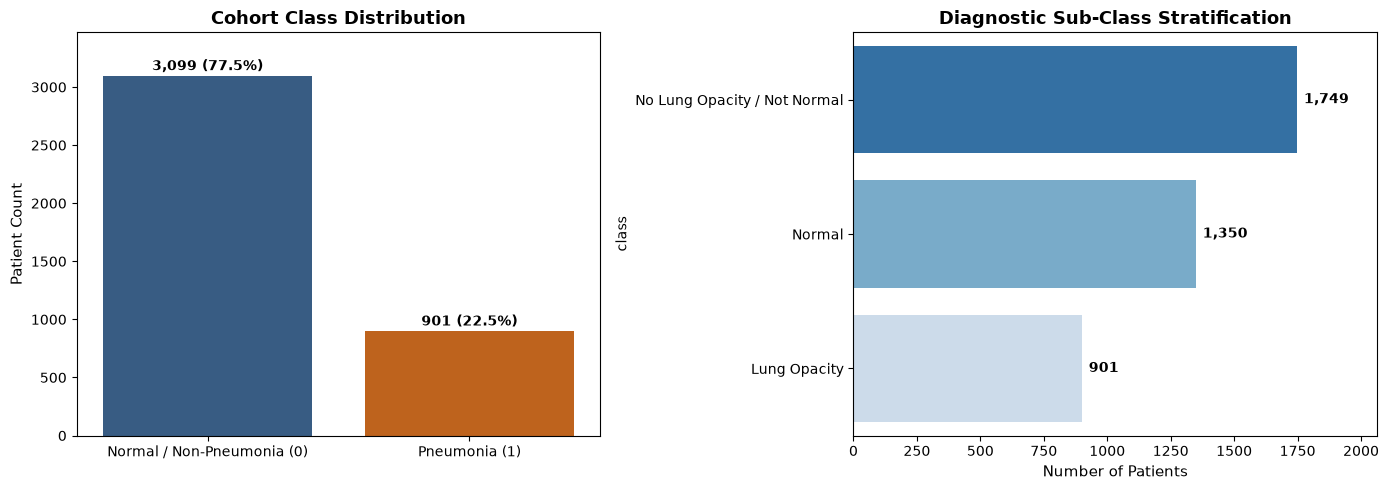

In [6]:
class_counts = df_cohort["label"].value_counts()
n_normal = int(class_counts.get(0, 0))
n_pneumonia = int(class_counts.get(1, 0))
imbalance_ratio = n_normal / max(n_pneumonia, 1)

print(f"Total Evaluated Patients   : {len(df_cohort):,}")
print(f"Normal / Non-Pneumonia (0) : {n_normal:,} ({n_normal/len(df_cohort):.2%})")
print(f"Pneumonia (1)              : {n_pneumonia:,} ({n_pneumonia/len(df_cohort):.2%})")
print(f"Class Imbalance Ratio      : {imbalance_ratio:.2f} : 1")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = ["#2b5c8f", "#d95f02"]
sns.barplot(x=["Normal / Non-Pneumonia (0)", "Pneumonia (1)"], y=[n_normal, n_pneumonia],
            hue=["Normal / Non-Pneumonia (0)", "Pneumonia (1)"], palette=palette, legend=False, ax=axes[0])
axes[0].set_title("Cohort Class Distribution", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Patient Count", fontsize=11)
for i, v in enumerate([n_normal, n_pneumonia]):
    axes[0].text(i, v + max(n_normal, n_pneumonia) * 0.015, f"{v:,} ({v/len(df_cohort):.1%})", ha="center", fontweight="bold")
axes[0].set_ylim(0, max(n_normal, n_pneumonia) * 1.12)

if "class" in df_cohort.columns:
    cat_counts = df_cohort["class"].value_counts()
    sns.barplot(x=cat_counts.values, y=cat_counts.index, hue=cat_counts.index,
                palette="Blues_r", legend=False, ax=axes[1])
    axes[1].set_title("Diagnostic Sub-Class Stratification", fontsize=13, fontweight="bold")
    axes[1].set_xlabel("Number of Patients", fontsize=11)
    axes[1].set_xlim(0, cat_counts.values.max() * 1.18)
    for i, v in enumerate(cat_counts.values):
        axes[1].text(v + cat_counts.values.max() * 0.015, i, f"{v:,}", va="center", fontweight="bold")
else:
    axes[1].pie([n_normal, n_pneumonia], labels=["Normal", "Pneumonia"], autopct="%1.1f%%", colors=palette, startangle=140)
    axes[1].set_title("Class Ratio Proportion", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()

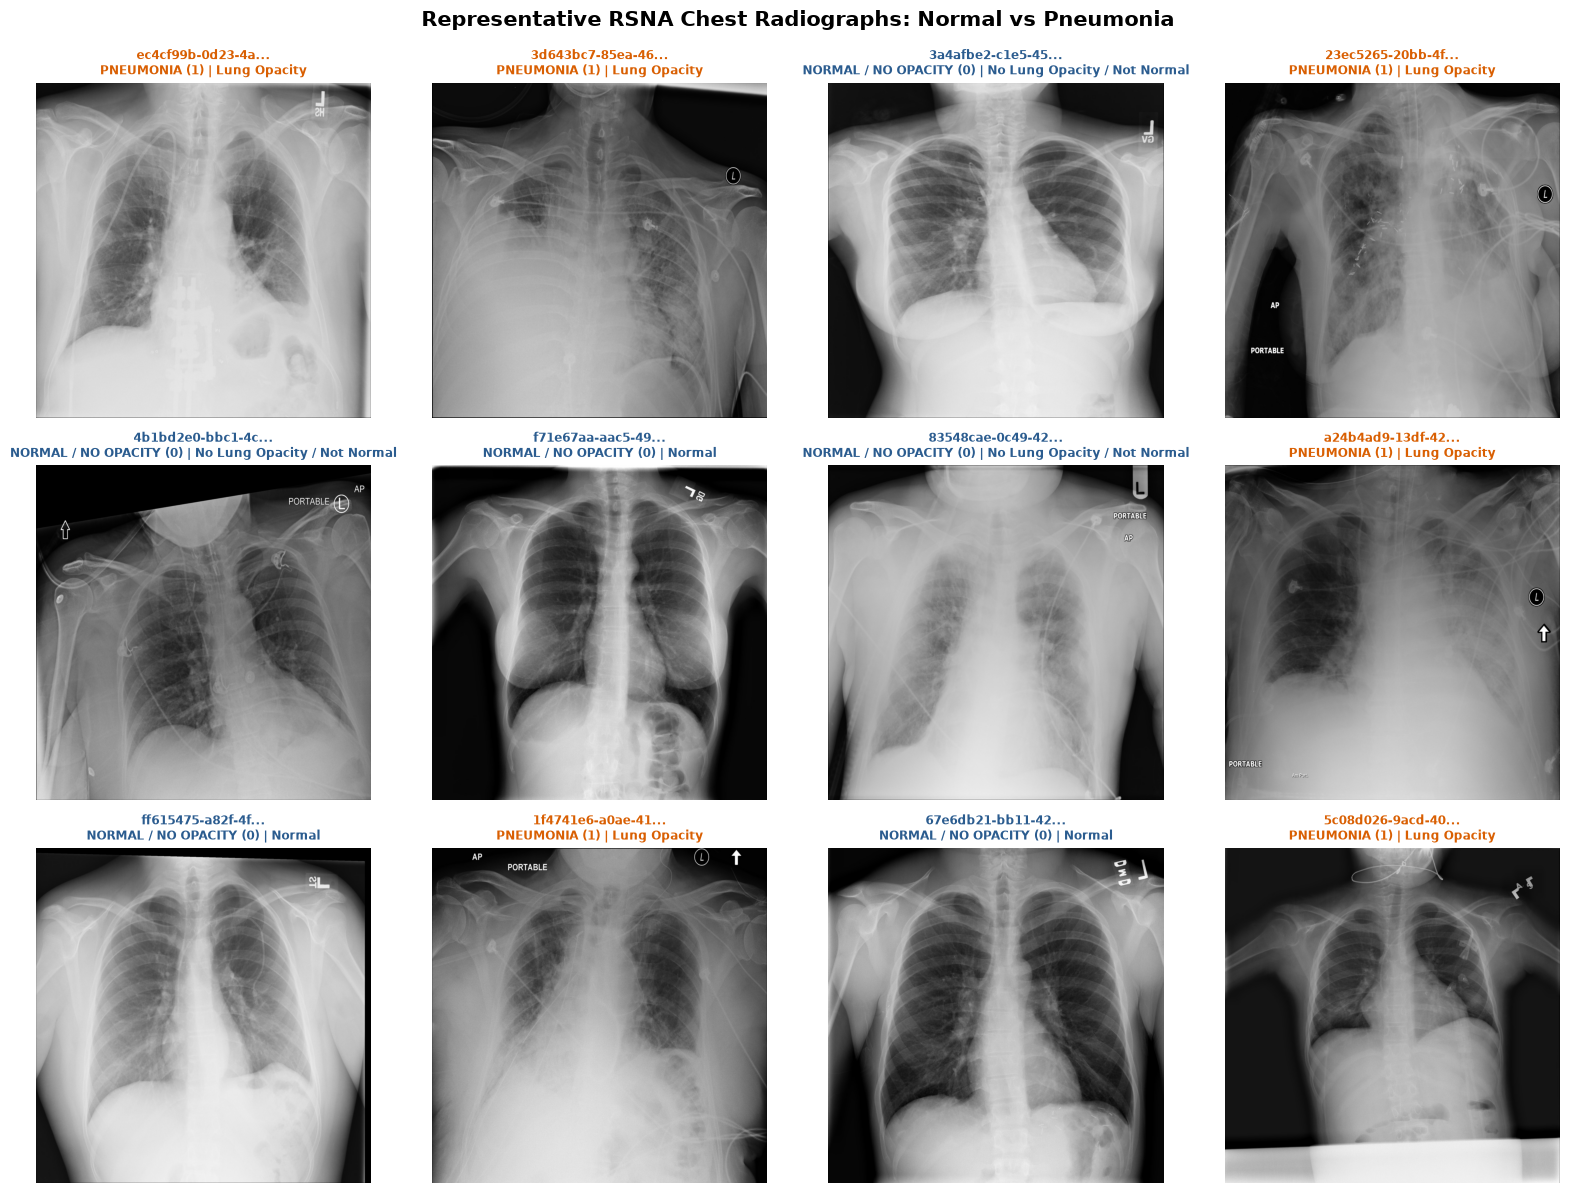

In [7]:
sample_norm = df_cohort[df_cohort["label"] == 0].sample(n=min(6, n_normal), random_state=SEED)
sample_pneu = df_cohort[df_cohort["label"] == 1].sample(n=min(6, n_pneumonia), random_state=SEED)
samples_display = pd.concat([sample_norm, sample_pneu]).sample(frac=1.0, random_state=SEED).reset_index(drop=True)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for idx, row in samples_display.iterrows():
    img_bgr = cv2.imread(row["image_path"])
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB) if img_bgr is not None else np.zeros((224, 224, 3), dtype=np.uint8)
    lbl_str = "PNEUMONIA (1)" if row["label"] == 1 else "NORMAL / NO OPACITY (0)"
    color = "#d95f02" if row["label"] == 1 else "#2b5c8f"
    sub_cls = row["class"] if "class" in row and pd.notna(row["class"]) else ""
    axes[idx].imshow(img_rgb)
    axes[idx].set_title(f"{row['patientId'][:16]}...\n{lbl_str} | {sub_cls}", fontsize=8.5, fontweight="bold", color=color)
    axes[idx].axis("off")

plt.suptitle("Representative RSNA Chest Radiographs: Normal vs Pneumonia", fontsize=15, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()

Normal Lung Pixel Intensity    : Mean = 124.77, Std = 63.99, Median = 131.0
Pneumonia Lung Pixel Intensity : Mean = 122.16, Std = 61.58, Median = 129.0


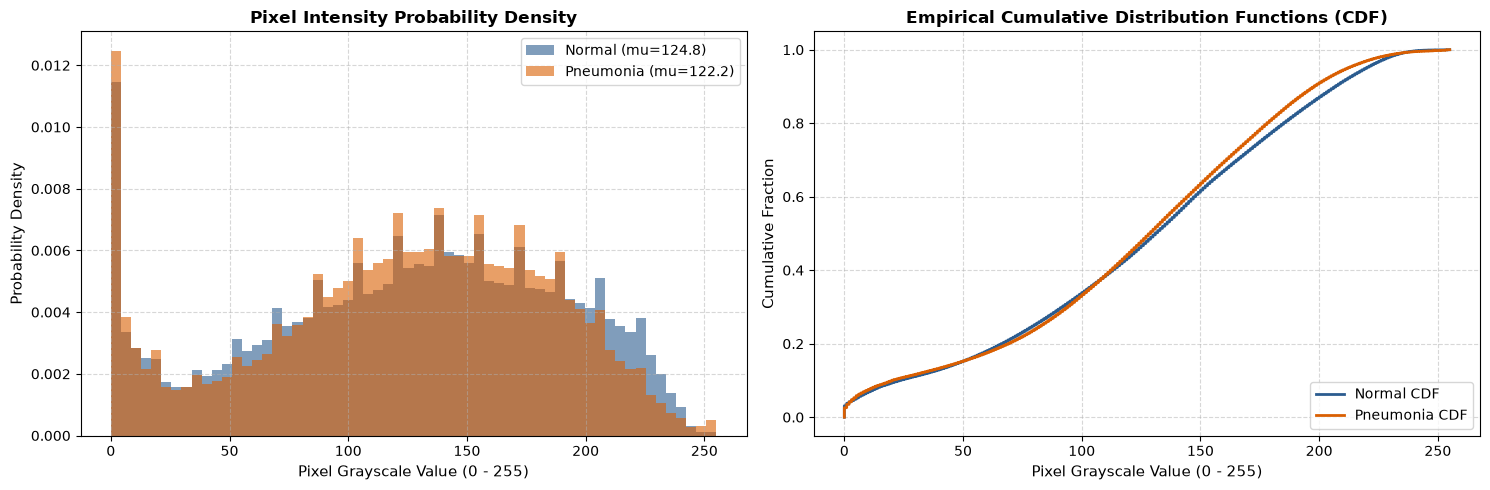

In [8]:
# Stratified sample of 200 Normal and 200 Pneumonia radiographs for pixel profiling
eda_norm = df_cohort[df_cohort["label"] == 0].sample(n=min(200, n_normal), random_state=SEED)
eda_pneu = df_cohort[df_cohort["label"] == 1].sample(n=min(200, n_pneumonia), random_state=SEED)
eda_df = pd.concat([eda_norm, eda_pneu])

normal_pixels = []
pneumonia_pixels = []
for _, row in eda_df.iterrows():
    img = cv2.imread(row["image_path"], cv2.IMREAD_GRAYSCALE)
    if img is not None:
        sub = img.flatten()[::32]
        if row["label"] == 1:
            pneumonia_pixels.append(sub)
        else:
            normal_pixels.append(sub)

normal_pixels = np.concatenate(normal_pixels)
pneumonia_pixels = np.concatenate(pneumonia_pixels)

norm_mean, norm_std = np.mean(normal_pixels), np.std(normal_pixels)
pneu_mean, pneu_std = np.mean(pneumonia_pixels), np.std(pneumonia_pixels)

print(f"Normal Lung Pixel Intensity    : Mean = {norm_mean:.2f}, Std = {norm_std:.2f}, Median = {np.median(normal_pixels):.1f}")
print(f"Pneumonia Lung Pixel Intensity : Mean = {pneu_mean:.2f}, Std = {pneu_std:.2f}, Median = {np.median(pneumonia_pixels):.1f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].hist(normal_pixels, bins=60, density=True, alpha=0.6, color="#2b5c8f", label=f"Normal (mu={norm_mean:.1f})")
axes[0].hist(pneumonia_pixels, bins=60, density=True, alpha=0.6, color="#d95f02", label=f"Pneumonia (mu={pneu_mean:.1f})")
axes[0].set_title("Pixel Intensity Probability Density", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Pixel Grayscale Value (0 - 255)", fontsize=11)
axes[0].set_ylabel("Probability Density", fontsize=11)
axes[0].legend(loc="upper right")
axes[0].grid(True, linestyle="--", alpha=0.5)

sorted_norm = np.sort(normal_pixels)
sorted_pneu = np.sort(pneumonia_pixels)
axes[1].plot(sorted_norm, np.linspace(0, 1, len(sorted_norm)), color="#2b5c8f", lw=2, label="Normal CDF")
axes[1].plot(sorted_pneu, np.linspace(0, 1, len(sorted_pneu)), color="#d95f02", lw=2, label="Pneumonia CDF")
axes[1].set_title("Empirical Cumulative Distribution Functions (CDF)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Pixel Grayscale Value (0 - 255)", fontsize=11)
axes[1].set_ylabel("Cumulative Fraction", fontsize=11)
axes[1].legend(loc="lower right")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

---
## 6. Data Cleaning & Patient-Level Stratified Partitioning

### 6.1 Preventing Data Leakage in Medical Imaging
Data leakage is a fatal flaw in clinical machine learning. If multiple images or longitudinal studies from the same patient are distributed across training and test splits, the convolutional network can inadvertently memorize idiosyncratic patient-specific anatomical features (e.g., distinctive thoracic width, osteophyte patterns, surgical clips, clavicular curvature) rather than learning generalized radiological features of pneumonia.

To ensure pristine clinical validity:
- We enforce a **strict patient-level partition**: all images belonging to a single `patientId` reside exclusively within one split.
- We utilize **stratified splitting** to maintain identical class ratios across:
  - **Training Cohort**: 70%
  - **Validation Cohort**: 15% (for model selection, learning rate decay, and threshold tuning)
  - **Test Cohort**: 15% (strictly held-out and untouched until final benchmarking)
- We computationally assert zero patient overlap across splits.

In [9]:
train_val_df, test_df = train_test_split(
    df_cohort,
    test_size=0.15,
    random_state=SEED,
    stratify=df_cohort["label"],
)

train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=train_val_df["label"],
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_pids = set(train_df["patientId"])
val_pids = set(val_df["patientId"])
test_pids = set(test_df["patientId"])

assert len(train_pids & val_pids) == 0, "[ERROR] Patient leakage between Train and Validation!"
assert len(train_pids & test_pids) == 0, "[ERROR] Patient leakage between Train and Test!"
assert len(val_pids & test_pids) == 0, "[ERROR] Patient leakage between Validation and Test!"

print("=" * 70)
print("PATIENT-LEVEL STRATIFIED PARTITION AUDIT:")
print(f"Training Cohort    : {len(train_df):5,d} patients ({len(train_df)/len(df_cohort):.1%}) | Pneumonia: {int(train_df['label'].sum()):4,d} ({train_df['label'].mean():.2%})")
print(f"Validation Cohort  : {len(val_df):5,d} patients ({len(val_df)/len(df_cohort):.1%}) | Pneumonia: {int(val_df['label'].sum()):4,d} ({val_df['label'].mean():.2%})")
print(f"Holdout Test Cohort: {len(test_df):5,d} patients ({len(test_df)/len(df_cohort):.1%}) | Pneumonia: {int(test_df['label'].sum()):4,d} ({test_df['label'].mean():.2%})")
print("Zero Patient Leakage Confirmed: True")
print("=" * 70)

PATIENT-LEVEL STRATIFIED PARTITION AUDIT:
Training Cohort    : 2,800 patients (70.0%) | Pneumonia:  631 (22.54%)
Validation Cohort  :   600 patients (15.0%) | Pneumonia:  135 (22.50%)
Holdout Test Cohort:   600 patients (15.0%) | Pneumonia:  135 (22.50%)
Zero Patient Leakage Confirmed: True


---
## 7. Data Preprocessing & Architecture Input Contracts

In this section, we define the core preprocessing parameters and address the fundamental requirement of architecture-specific input scaling.

### 7.1 Input Preprocessing Requirements Across Architectures
Pretrained deep learning architectures expect specific input normalization contracts. Applying mismatched normalization degrades transfer learning representations:
- **Custom CNN (Model A)**: Native $[0, 1]$ scaling via $\frac{x}{255.0}$.
- **ImageNet Transfer Backbones (Models B–E: VGG16, ResNet50, MobileNetV2, EfficientNetB0)**: Channel-wise ImageNet standardization after $[0, 1]$ scaling:
  $$x_{\text{norm}} = \frac{x_{[0,1]} - \mu}{\sigma}, \quad \mu = [0.485, 0.456, 0.406], \quad \sigma = [0.229, 0.224, 0.225]$$

By encapsulating architecture-specific normalization inside each model's forward pass, all five architectures share a unified, deterministic `[0, 1]` `(B, 3, 224, 224)` dataloader contract, preventing normalization mismatches during evaluation, Grad-CAM, or perturbation stress testing.

In [10]:
IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)
BATCH_SIZE = 32
CHANNELS = 3

print("Configured Hyperparameters:")
print(f"Target Image Dimensions : {IMG_SIZE} (Channels = {CHANNELS})")
print(f"Mini-Batch Size         : {BATCH_SIZE}")
print(f"Random Seed             : {SEED}")

def load_and_preprocess_single_image(image_path, target_size=(224, 224)):
    """
    Robust standalone image reader converting single-channel grayscale
    radiographs into 3-channel uint8 RGB arrays with bilinear interpolation.
    """
    try:
        img = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
        if img is None:
            with Image.open(image_path) as pil_img:
                img = np.array(pil_img.convert("RGB"))
        else:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img, target_size, interpolation=cv2.INTER_LINEAR)
        return img_resized
    except Exception as e:
        print(f"[ERROR] Failed to read {image_path}: {e}")
        return np.zeros((target_size[0], target_size[1], 3), dtype=np.uint8)

sample_img = load_and_preprocess_single_image(train_df["image_path"].iloc[0], IMG_SIZE)
print(f"Sample Processed Image Shape: {sample_img.shape}, Dtype: {sample_img.dtype}, Range: [{sample_img.min()}, {sample_img.max()}]")

Configured Hyperparameters:
Target Image Dimensions : (224, 224) (Channels = 3)
Mini-Batch Size         : 32
Random Seed             : 42
Sample Processed Image Shape: (224, 224, 3), Dtype: uint8, Range: [0, 244]


---
## 8. Clinically Sound Data Augmentation Pipeline

Data augmentation introduces synthetic variability into training batches, preventing deep networks from overfitting to subtle technical artifacts. However, in medical imaging, augmentations **must strictly adhere to anatomical and clinical plausibility**:

### 8.1 Permissible Medical Transformations
- **Random Horizontal Flip**: Medically justified because human thoracic anatomy is bilaterally symmetric. Although situs inversus occurs rarely ($<0.01\%$), consolidating opacities manifest identically across right and left lung fields.
- **Small Rotation ($\pm 7^\circ$)**: Simulates minor patient rotation and tilt frequently encountered during bedside portable anteroposterior (AP) chest radiography.
- **Small Translation ($\pm 5\%$)**: Mimics detector centering and patient framing variations.
- **Small Zoom ($[0.95, 1.05]$)**: Accounts for slight variations in focal-film distance (FFD).
- **Brightness & Contrast Adjustments ($\pm 10\%$)**: Simulates differences in radiographic exposure parameters (tube voltage $kVp$ and product $mAs$).

### 8.2 Prohibited Transformations
- **Vertical Flip**: STRICTLY PROHIBITED. Thoracic anatomy is non-invertible under gravity (e.g., pleural effusions collect basally, pneumothoraces rise apically).
- **Aggressive Cutout / Random Erasing**: PROHIBITED. Can excise focal consolidating lesions or artificially simulate cavitation/pneumothorax.

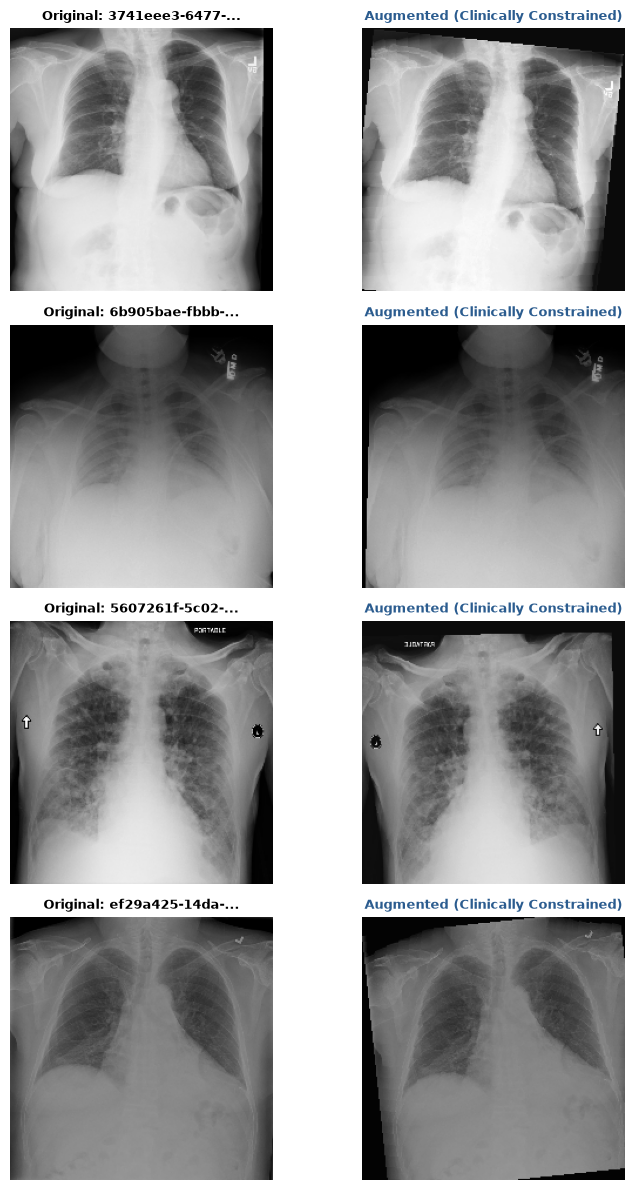

In [11]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=7, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.10, contrast=0.10),
    transforms.ToTensor(),  # uint8 [0, 255] -> float32 [0.0, 1.0], (3, H, W)
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
])

# Demonstrate Augmentation on 4 Clinical Samples
demo_indices = [0, 1, 2, 3]
fig, axes = plt.subplots(4, 2, figsize=(8, 12))

torch.manual_seed(SEED)
for row_idx, data_idx in enumerate(demo_indices):
    raw_img = load_and_preprocess_single_image(train_df["image_path"].iloc[data_idx], IMG_SIZE)
    pil_img = Image.fromarray(raw_img)
    aug_tensor = train_transform(pil_img)
    aug_img = (aug_tensor.permute(1, 2, 0).numpy() * 255.0).clip(0, 255).astype(np.uint8)

    axes[row_idx, 0].imshow(raw_img)
    axes[row_idx, 0].set_title(f"Original: {train_df['patientId'].iloc[data_idx][:14]}...", fontsize=9, fontweight="bold")
    axes[row_idx, 0].axis("off")

    axes[row_idx, 1].imshow(aug_img)
    axes[row_idx, 1].set_title("Augmented (Clinically Constrained)", fontsize=9, fontweight="bold", color="#2b5c8f")
    axes[row_idx, 1].axis("off")

plt.tight_layout()
plt.show()

---
## 9. High-Throughput Reusable Data Pipeline (`Dataset` & `DataLoader`)

Because raw RSNA radiographs are stored as $1024 \times 1024$ PNG files (`>10 GB` total on disk), repeatedly decoding and resizing large PNGs from disk every epoch creates a severe CPU I/O bottleneck. To keep the RTX 5050 GPU saturated:
- **Parallel One-Time Pre-Resize Cache**: All cohort radiographs are decoded and bilinearly resized to $224 \times 224$ `uint8` grayscale once in parallel (`~200 MB` RAM for 4,000 patients), with automatic fallback to lazy disk loading if running very large cohorts (`>8,000` images).
- **Pinned Memory Host-to-Device Transfers**: `pin_memory=True` accelerates asynchronous batch transfers to CUDA.
- **Deterministic Validation/Testing**: Validation and holdout test loaders strictly disable shuffling and augmentation for reproducible benchmarking.
- **Class Imbalance Weighting**: Balanced class weights counteract label disparity ($3.44:1$) via `BCEWithLogitsLoss(pos_weight=...)`:
  $$w_c = \frac{N}{2 \times N_c}$$

In [12]:
classes = np.unique(train_df["label"])
weights = compute_class_weight(class_weight="balanced", classes=classes, y=train_df["label"].values)
class_weights_dict = {int(c): float(w) for c, w in zip(classes, weights)}
POS_WEIGHT_VALUE = float(class_weights_dict[1] / class_weights_dict[0])
print(f"Computed Class Weights: {class_weights_dict}")
print(f"BCEWithLogits pos_weight (1 vs 0): {POS_WEIGHT_VALUE:.4f}")

# Pre-resize cohort images into memory if <= 8000 patients for ultra-fast GPU training
IMAGE_CACHE = {}
if len(df_cohort) <= 8000:
    t_cache = time.time()
    def _load_gray_224(item):
        pid, path = item
        im = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        if im is None:
            with Image.open(path) as pil_im:
                im = np.array(pil_im.convert("L"))
        return pid, cv2.resize(im, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_LINEAR)

    pairs = list(zip(df_cohort["patientId"].tolist(), df_cohort["image_path"].tolist()))
    with ThreadPoolExecutor(max_workers=12) as ex:
        for pid, arr in ex.map(_load_gray_224, pairs):
            IMAGE_CACHE[pid] = arr
    cache_mb = sum(a.nbytes for a in IMAGE_CACHE.values()) / (1024**2)
    print(f"[CACHE] Pre-resized {len(IMAGE_CACHE):,} images to {IMG_SIZE} in {time.time() - t_cache:.2f}s ({cache_mb:.1f} MB RAM)")

class ChestXrayDataset(Dataset):
    def __init__(self, frame, transform=None, cache=None):
        self.pids = frame["patientId"].tolist()
        self.paths = frame["image_path"].tolist()
        self.labels = frame["label"].astype(np.float32).tolist()
        self.transform = transform
        self.cache = cache or {}

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        pid = self.pids[idx]
        if pid in self.cache:
            gray = self.cache[pid]
            pil_img = Image.fromarray(gray, mode="L").convert("RGB")
        else:
            arr = load_and_preprocess_single_image(self.paths[idx], IMG_SIZE)
            pil_img = Image.fromarray(arr, mode="RGB")
        tensor = self.transform(pil_img) if self.transform else transforms.ToTensor()(pil_img)
        return tensor, torch.tensor(self.labels[idx], dtype=torch.float32)

train_ds = ChestXrayDataset(train_df, transform=train_transform, cache=IMAGE_CACHE)
val_ds   = ChestXrayDataset(val_df,   transform=eval_transform,  cache=IMAGE_CACHE)
test_ds  = ChestXrayDataset(test_df,  transform=eval_transform,  cache=IMAGE_CACHE)

PIN_MEMORY = (DEVICE.type == "cuda")
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=PIN_MEMORY)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=PIN_MEMORY)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=PIN_MEMORY)

sample_x, sample_y = next(iter(train_loader))
print(f"Batched Tensor Shape : X = {tuple(sample_x.shape)}, Y = {tuple(sample_y.shape)}")
print(f"Batch Dynamic Range  : Min = {sample_x.min().item():.3f}, Max = {sample_x.max().item():.3f}, Dtype = {sample_x.dtype}")

Computed Class Weights: {0: 0.6454587367450438, 1: 2.218700475435816}
BCEWithLogits pos_weight (1 vs 0): 3.4374


[CACHE] Pre-resized 4,000 images to (224, 224) in 3.30s (191.4 MB RAM)
Batched Tensor Shape : X = (32, 3, 224, 224), Y = (32,)
Batch Dynamic Range  : Min = 0.000, Max = 1.000, Dtype = torch.float32


---
## 10. Model A: Custom Deep Convolutional Neural Network (CNN)

To establish an empirical baseline designed from first principles specifically for grayscale thoracic radiographs, we engineer a 4-stage convolutional neural network:
- **Feature Extraction Hierarchy**: Progressively extracts low-level edges and rib contours (32 filters), bronchial branchings (64 filters), intermediate textural opacities (128 filters), and high-level consolidative patterns (256 filters).
- **Stabilization & Regularization**: Each stage employs Batch Normalization to mitigate internal covariate shift, followed by ReLU non-linearities and spatial Max Pooling.
- **Overfitting Mitigation**: Progressive spatial dropout ($0.20 \rightarrow 0.35$) prevents co-adaptation of feature maps.
- **Classification Head**: Global Average Pooling collapses spatial feature maps into a 1D vector (substantially reducing parameter count and spatial bias compared to Flatten), followed by a dense layer with Dropout ($0.50$) and a single linear logit unit (paired with `BCEWithLogitsLoss`).

In [13]:
def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

class CustomCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.model_name = "Custom_CNN"
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d(2), nn.Dropout2d(0.20),
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2), nn.Dropout2d(0.25),
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.MaxPool2d(2), nn.Dropout2d(0.30),
        )
        self.block4 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.MaxPool2d(2), nn.Dropout2d(0.35),
        )
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128, bias=False),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.50),
            nn.Linear(128, 1),
        )

    def get_gradcam_target_layer(self):
        return self.block4[2]  # Post-Conv2d+BN+ReLU feature map (before MaxPool2d)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.gap(x)
        return self.head(x).squeeze(1)

class ImageNetBackboneWrapper(nn.Module):
    """Wraps a torchvision ImageNet backbone with standardized ImageNet normalization."""
    def __init__(self, model_name, backbone, gradcam_layer):
        super().__init__()
        self.model_name = model_name
        self.backbone = backbone
        # Store inside a plain list so PyTorch does not duplicate submodule weights in state_dict
        self._gradcam_layer_ref = [gradcam_layer]
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def get_gradcam_target_layer(self):
        return self._gradcam_layer_ref[0]

    def forward(self, x):
        x = (x - self.mean) / self.std
        return self.backbone(x).squeeze(1)

model_a = CustomCNN()
tot_a, trn_a = count_parameters(model_a)
print(f"Model A Architecture : {model_a.model_name}")
print(f"Total Parameters     : {tot_a:,}")
print(f"Trainable Parameters : {trn_a:,}")

Model A Architecture : Custom_CNN
Total Parameters     : 616,033
Trainable Parameters : 616,033


---
## 11. Model B: VGG16 Transfer Learning Architecture

VGG16 (Visual Geometry Group, Oxford) relies on homogenous $3 \times 3$ convolutional filter stacks. While computationally heavy, its linear feature hierarchy preserves fine localized spatial gradients valuable for radiomic boundary detection.

### 11.1 Two-Stage Transfer Learning Protocol
1. **Stage 1 (Feature Extraction)**: The ImageNet `features` backbone is completely frozen (`requires_grad = False`). Global Average Pooling + custom dense classification head is trained using AdamW ($\eta = 10^{-3}$).
2. **Stage 2 (Fine-Tuning)**: The deepest convolutional block (`block5`: `features[24:]`) is unfrozen, allowing high-level filters to adapt to pulmonary radiograph features under a low learning rate ($\eta = 5 \times 10^{-5}$).

In [14]:
def build_vgg16():
    base_vgg = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
    for p in base_vgg.features.parameters():
        p.requires_grad = False
    base_vgg.avgpool = nn.AdaptiveAvgPool2d((1, 1))
    base_vgg.classifier = nn.Sequential(
        nn.Linear(512, 256),
        nn.ReLU(inplace=True),
        nn.BatchNorm1d(256),
        nn.Dropout(0.50),
        nn.Linear(256, 64),
        nn.ReLU(inplace=True),
        nn.Dropout(0.30),
        nn.Linear(64, 1),
    )
    model = ImageNetBackboneWrapper("VGG16", base_vgg, base_vgg.features[29])
    return model

model_b = build_vgg16()
tot_b, trn_b = count_parameters(model_b)
print(f"Model B Architecture           : {model_b.model_name}")
print(f"Total Parameters               : {tot_b:,}")
print(f"Trainable Parameters (Stage 1) : {trn_b:,}")

Model B Architecture           : VGG16
Total Parameters               : 14,863,041
Trainable Parameters (Stage 1) : 148,353


---
## 12. Model C: ResNet50 Transfer Learning Architecture

ResNet50 introduces identity shortcut (skip) connections that allow residual mapping:
$$\mathcal{H}(x) = \mathcal{F}(x) + x$$
This directly resolves the vanishing gradient degradation problem, enabling deep feature propagation through 50 layers.

### 12.1 Two-Stage Transfer Learning Protocol
1. **Stage 1**: Freeze backbone, optimize custom classification head with AdamW ($\eta = 10^{-3}$).
2. **Stage 2**: Unfreeze the final residual stage (`layer4`, keeping pretrained BatchNorm running statistics fixed) to fine-tune high-level thoracic consolidation representations with AdamW ($\eta = 5 \times 10^{-5}$).

In [15]:
def build_resnet50():
    base_resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    for p in base_resnet.parameters():
        p.requires_grad = False
    in_feat = base_resnet.fc.in_features
    base_resnet.fc = nn.Sequential(
        nn.Linear(in_feat, 256),
        nn.ReLU(inplace=True),
        nn.BatchNorm1d(256),
        nn.Dropout(0.50),
        nn.Linear(256, 1),
    )
    model = ImageNetBackboneWrapper("ResNet50", base_resnet, base_resnet.layer4[-1])
    return model

model_c = build_resnet50()
tot_c, trn_c = count_parameters(model_c)
print(f"Model C Architecture           : {model_c.model_name}")
print(f"Total Parameters               : {tot_c:,}")
print(f"Trainable Parameters (Stage 1) : {trn_c:,}")

Model C Architecture           : ResNet50
Total Parameters               : 24,033,345
Trainable Parameters (Stage 1) : 525,313


---
## 13. Model D: MobileNetV2 (Edge / Point-of-Care Architecture)

MobileNetV2 is specifically designed for resource-constrained clinical environments (e.g., portable bedside imaging carts, mobile screening vans, low-power tablet workstations).
- **Depthwise Separable Convolutions**: Factorizes standard convolutions into depthwise spatial filtering and pointwise $1 \times 1$ channel combinations, slashing FLOPs by over 80%.
- **Inverted Residuals & Linear Bottlenecks**: Expands to higher-dimensional space internally before compressing back to a linear bottleneck, preventing non-linearities from destroying manifold representations.

In [16]:
def build_mobilenet_v2():
    base_mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
    for p in base_mobilenet.parameters():
        p.requires_grad = False
    in_feat = base_mobilenet.last_channel
    base_mobilenet.classifier = nn.Sequential(
        nn.Linear(in_feat, 128),
        nn.ReLU(inplace=True),
        nn.BatchNorm1d(128),
        nn.Dropout(0.40),
        nn.Linear(128, 1),
    )
    model = ImageNetBackboneWrapper("MobileNetV2", base_mobilenet, base_mobilenet.features[-1])
    return model

model_d = build_mobilenet_v2()
tot_d, trn_d = count_parameters(model_d)
print(f"Model D Architecture           : {model_d.model_name}")
print(f"Total Parameters               : {tot_d:,}")
print(f"Trainable Parameters (Stage 1) : {trn_d:,}")

Model D Architecture           : MobileNetV2
Total Parameters               : 2,388,225
Trainable Parameters (Stage 1) : 164,353


---
## 14. Model E: EfficientNetB0 (Compound Scaling Architecture)

EfficientNetB0 introduces principled compound scaling, uniformly scaling network depth ($d$), width ($w$), and input resolution ($r$) via a fixed compound coefficient:
$$\text{depth}: d = \alpha^\phi, \quad \text{width}: w = \beta^\phi, \quad \text{resolution}: r = \gamma^\phi$$
subject to $\alpha \cdot \beta^2 \cdot \gamma^2 \approx 2$. It incorporates MBConv (Mobile Inverted Bottleneck Convolution) blocks equipped with Squeeze-and-Excitation (SE) attention mechanisms to adaptively re-weight channel feature maps.

In [17]:
def build_efficientnet_b0():
    base_efficientnet = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
    for p in base_efficientnet.parameters():
        p.requires_grad = False
    in_feat = base_efficientnet.classifier[1].in_features
    base_efficientnet.classifier = nn.Sequential(
        nn.BatchNorm1d(in_feat),
        nn.Dropout(0.40),
        nn.Linear(in_feat, 128),
        nn.ReLU(inplace=True),
        nn.Dropout(0.30),
        nn.Linear(128, 1),
    )
    model = ImageNetBackboneWrapper("EfficientNetB0", base_efficientnet, base_efficientnet.features[-1])
    return model

model_e = build_efficientnet_b0()
tot_e, trn_e = count_parameters(model_e)
print(f"Model E Architecture           : {model_e.model_name}")
print(f"Total Parameters               : {tot_e:,}")
print(f"Trainable Parameters (Stage 1) : {trn_e:,}")

Model E Architecture           : EfficientNetB0
Total Parameters               : 4,174,205
Trainable Parameters (Stage 1) : 166,657


---
## 15. Model Training Optimization, Two-Stage Schedules & Callbacks

In this section, we establish a unified, modular PyTorch GPU training harness supporting both single-stage training (Custom CNN) and two-stage transfer learning protocols (VGG16, ResNet50, MobileNetV2, EfficientNetB0):

### 15.1 Optimization Strategy
- **Stage 1 (Feature Extraction)**:
  - Backbone frozen. Classification head trained with AdamW ($\eta_1 = 1 \times 10^{-3}$, weight decay $10^{-4}$).
  - Stabilizes top dense classification layers before any backbone gradients are propagated.
- **Stage 2 (Targeted Fine-Tuning)**:
  - Deepest convolutional blocks unfrozen (`VGG16`: `block5`, `ResNet50`: `layer4`, `MobileNetV2`: last 5 blocks, `EfficientNetB0`: last 3 blocks), while preserving ImageNet BatchNorm running statistics.
  - Optimized with low-rate AdamW ($\eta_2 = 5 \times 10^{-5}$) to align high-level semantic filters with pulmonary consolidation patterns.

### 15.2 Regularization & Adaptive Scheduling
- **`EarlyStopping`**: Monitors `val_loss` with patience $= 5$; halts training when validation loss stops improving and restores optimal network weights.
- **`ReduceLROnPlateau`**: Monitors `val_loss` with factor $= 0.5$, patience $= 2$, and $\min(\eta) = 10^{-7}$.
- **`ModelCheckpoint`**: Serializes the best model weights (`models/checkpoint_<model>.pth`) based on validation performance.

In [18]:
TRAINING_HISTORIES = {}
TRAINING_TIMES = {}

def _unfreeze_top_backbone_blocks(model, model_name):
    if model_name == "VGG16":
        for p in model.backbone.features[24:].parameters():
            p.requires_grad = True
    elif model_name == "ResNet50":
        for p in model.backbone.layer4.parameters():
            p.requires_grad = True
    elif model_name == "MobileNetV2":
        for p in model.backbone.features[-5:].parameters():
            p.requires_grad = True
    elif model_name == "EfficientNetB0":
        for p in model.backbone.features[-3:].parameters():
            p.requires_grad = True

def _keep_backbone_bn_eval(model, model_name):
    """Keep BatchNorm running stats frozen inside ImageNet backbones during fine-tuning."""
    if model_name == "Custom_CNN":
        return
    for name, module in model.backbone.named_modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

def _run_one_epoch(model, loader, criterion, optimizer=None, scaler=None, model_name="Model"):
    is_train = optimizer is not None
    model.train(is_train)
    if is_train:
        _keep_backbone_bn_eval(model, model_name)

    total_loss = 0.0
    all_probs, all_labels = [], []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_train):
            with torch.amp.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(images)
                loss = criterion(logits, labels)

            if is_train:
                if USE_AMP and scaler is not None:
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    optimizer.step()

        total_loss += loss.item() * labels.size(0)
        probs = torch.sigmoid(logits.detach()).float().cpu().numpy()
        all_probs.extend(probs.tolist())
        all_labels.extend(labels.detach().cpu().numpy().tolist())

    avg_loss = total_loss / max(len(loader.dataset), 1)
    y_true = np.asarray(all_labels)
    y_prob = np.asarray(all_probs)
    acc = accuracy_score(y_true, (y_prob >= 0.50).astype(int))
    auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else 0.5
    return avg_loss, acc, auc

def train_two_stage_model(
    model,
    model_name="Model",
    stage1_epochs=10,
    stage2_epochs=8,
    lr_stage1=1e-3,
    lr_stage2=5e-5,
    patience=5,
):
    """
    Execute unified single-stage (Custom_CNN) or two-stage transfer learning
    on GPU with AMP, class weighting, LR plateau scheduling, and best-checkpoint restoration.
    """
    start_time = time.time()
    model = model.to(DEVICE)
    checkpoint_path = MODELS_DIR / f"checkpoint_{model_name.lower()}.pth"
    pos_weight = torch.tensor(POS_WEIGHT_VALUE, device=DEVICE, dtype=torch.float32)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    history = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": [], "auc": [], "val_auc": [], "stage1_epochs": 0}
    global_best_val_loss = float("inf")
    global_best_state = copy.deepcopy(model.state_dict())

    print(f"\n{'='*70}")
    print(f"STARTING TRAINING: {model_name}")
    print(f"Stage 1: {'End-to-End' if model_name == 'Custom_CNN' else 'Frozen Backbone'} ({stage1_epochs} Epochs, LR={lr_stage1:.0e})")
    print(f"{'='*70}")

    opt1 = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr_stage1, weight_decay=1e-4)
    sched1 = torch.optim.lr_scheduler.ReduceLROnPlateau(opt1, mode="min", factor=0.5, patience=2, min_lr=1e-7)

    stage1_patience_cnt = 0
    for epoch in range(stage1_epochs):
        tr_loss, tr_acc, tr_auc = _run_one_epoch(model, train_loader, criterion, opt1, scaler, model_name)
        va_loss, va_acc, va_auc = _run_one_epoch(model, val_loader, criterion, model_name=model_name)
        sched1.step(va_loss)

        history["loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["accuracy"].append(tr_acc)
        history["val_accuracy"].append(va_acc)
        history["auc"].append(tr_auc)
        history["val_auc"].append(va_auc)
        history["stage1_epochs"] += 1

        print(f"  [S1] Epoch {epoch+1:02d}/{stage1_epochs:02d} | loss={tr_loss:.4f} acc={tr_acc:.4f} auc={tr_auc:.4f} | val_loss={va_loss:.4f} val_acc={va_acc:.4f} val_auc={va_auc:.4f}")

        if va_loss < global_best_val_loss - 1e-4:
            global_best_val_loss = va_loss
            global_best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save(global_best_state, checkpoint_path)
            stage1_patience_cnt = 0
        else:
            stage1_patience_cnt += 1
            if stage1_patience_cnt >= patience:
                print(f"  [S1] Early stopping triggered at epoch {epoch+1}.")
                break

    # Restore best Stage 1 weights before Stage 2
    model.load_state_dict({k: v.to(DEVICE) for k, v in global_best_state.items()})

    if model_name != "Custom_CNN" and stage2_epochs > 0:
        _unfreeze_top_backbone_blocks(model, model_name)
        _, trn_s2 = count_parameters(model)
        print(f"\nStage 2: Selective Backbone Fine-Tuning ({stage2_epochs} Epochs, LR={lr_stage2:.0e}, Trainable={trn_s2:,})")

        opt2 = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr_stage2, weight_decay=1e-4)
        sched2 = torch.optim.lr_scheduler.ReduceLROnPlateau(opt2, mode="min", factor=0.5, patience=2, min_lr=1e-8)

        stage2_patience_cnt = 0
        for epoch in range(stage2_epochs):
            tr_loss, tr_acc, tr_auc = _run_one_epoch(model, train_loader, criterion, opt2, scaler, model_name)
            va_loss, va_acc, va_auc = _run_one_epoch(model, val_loader, criterion, model_name=model_name)
            sched2.step(va_loss)

            history["loss"].append(tr_loss)
            history["val_loss"].append(va_loss)
            history["accuracy"].append(tr_acc)
            history["val_accuracy"].append(va_acc)
            history["auc"].append(tr_auc)
            history["val_auc"].append(va_auc)

            print(f"  [S2] Epoch {epoch+1:02d}/{stage2_epochs:02d} | loss={tr_loss:.4f} acc={tr_acc:.4f} auc={tr_auc:.4f} | val_loss={va_loss:.4f} val_acc={va_acc:.4f} val_auc={va_auc:.4f}")

            if va_loss < global_best_val_loss - 1e-4:
                global_best_val_loss = va_loss
                global_best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                torch.save(global_best_state, checkpoint_path)
                stage2_patience_cnt = 0
            else:
                stage2_patience_cnt += 1
                if stage2_patience_cnt >= patience:
                    print(f"  [S2] Early stopping triggered at epoch {epoch+1}.")
                    break

        model.load_state_dict({k: v.to(DEVICE) for k, v in global_best_state.items()})

    model.eval()
    elapsed_time = time.time() - start_time
    TRAINING_HISTORIES[model_name] = history
    TRAINING_TIMES[model_name] = elapsed_time
    print(f"Completed training {model_name} in {elapsed_time:.1f}s (Best Val Loss = {global_best_val_loss:.4f}).")
    return model

# Train Custom CNN (Model A) - Single-stage training
print("[TRAINING] Training Model A (Custom CNN)...")
model_a = train_two_stage_model(model_a, model_name="Custom_CNN", stage1_epochs=15, stage2_epochs=0, lr_stage1=1e-3, patience=5)

[TRAINING] Training Model A (Custom CNN)...

STARTING TRAINING: Custom_CNN
Stage 1: End-to-End (15 Epochs, LR=1e-03)


  [S1] Epoch 01/15 | loss=1.0849 acc=0.5436 auc=0.5862 | val_loss=1.0766 val_acc=0.7017 val_auc=0.6316


  [S1] Epoch 02/15 | loss=1.0840 acc=0.5275 auc=0.5798 | val_loss=1.0262 val_acc=0.6717 val_auc=0.6662


  [S1] Epoch 03/15 | loss=1.0760 acc=0.5311 auc=0.5696 | val_loss=1.0232 val_acc=0.5517 val_auc=0.6972


  [S1] Epoch 04/15 | loss=1.0346 acc=0.5768 auc=0.6354 | val_loss=1.0106 val_acc=0.5367 val_auc=0.7083


  [S1] Epoch 05/15 | loss=1.0346 acc=0.5718 auc=0.6315 | val_loss=0.9985 val_acc=0.6050 val_auc=0.6951


... (6 outputs left out)

  [S1] Epoch 12/15 | loss=0.9670 acc=0.6357 auc=0.7102 | val_loss=0.9150 val_acc=0.7333 val_auc=0.7689


  [S1] Epoch 13/15 | loss=0.9739 acc=0.6300 auc=0.7073 | val_loss=0.9392 val_acc=0.7367 val_auc=0.7603


  [S1] Epoch 14/15 | loss=0.9663 acc=0.6429 auc=0.7147 | val_loss=0.9183 val_acc=0.5967 val_auc=0.7726


  [S1] Epoch 15/15 | loss=0.9477 acc=0.6386 auc=0.7271 | val_loss=0.8878 val_acc=0.7183 val_auc=0.7777
Completed training Custom_CNN in 238.8s (Best Val Loss = 0.8878).


In [19]:
print("[TRAINING] Training Model B (VGG16)...")
model_b = train_two_stage_model(model_b, model_name="VGG16", stage1_epochs=8, stage2_epochs=8, lr_stage1=1e-3, lr_stage2=5e-5, patience=4)

print("[TRAINING] Training Model C (ResNet50)...")
model_c = train_two_stage_model(model_c, model_name="ResNet50", stage1_epochs=8, stage2_epochs=8, lr_stage1=1e-3, lr_stage2=5e-5, patience=4)

print("[TRAINING] Training Model D (MobileNetV2)...")
model_d = train_two_stage_model(model_d, model_name="MobileNetV2", stage1_epochs=8, stage2_epochs=8, lr_stage1=1e-3, lr_stage2=5e-5, patience=4)

print("[TRAINING] Training Model E (EfficientNetB0)...")
model_e = train_two_stage_model(model_e, model_name="EfficientNetB0", stage1_epochs=8, stage2_epochs=8, lr_stage1=1e-3, lr_stage2=5e-5, patience=4)

gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

[TRAINING] Training Model B (VGG16)...

STARTING TRAINING: VGG16
Stage 1: Frozen Backbone (8 Epochs, LR=1e-03)


  [S1] Epoch 01/08 | loss=0.9154 acc=0.6911 auc=0.7580 | val_loss=0.8591 val_acc=0.7333 val_auc=0.7945


  [S1] Epoch 02/08 | loss=0.8440 acc=0.7086 auc=0.8024 | val_loss=0.8450 val_acc=0.7267 val_auc=0.8011


  [S1] Epoch 03/08 | loss=0.8204 acc=0.7246 auc=0.8135 | val_loss=0.8237 val_acc=0.7533 val_auc=0.8141


  [S1] Epoch 04/08 | loss=0.8116 acc=0.7200 auc=0.8200 | val_loss=0.8466 val_acc=0.7483 val_auc=0.8107


  [S1] Epoch 05/08 | loss=0.7945 acc=0.7304 auc=0.8267 | val_loss=0.8204 val_acc=0.7567 val_auc=0.8146


... (46 outputs left out)

  [S2] Epoch 02/08 | loss=0.7456 acc=0.7518 auc=0.8479 | val_loss=0.7651 val_acc=0.7850 val_auc=0.8426


  [S2] Epoch 03/08 | loss=0.6955 acc=0.7671 auc=0.8720 | val_loss=0.7612 val_acc=0.7100 val_auc=0.8466


  [S2] Epoch 04/08 | loss=0.6775 acc=0.7743 auc=0.8784 | val_loss=0.7707 val_acc=0.7750 val_auc=0.8454


  [S2] Epoch 05/08 | loss=0.6562 acc=0.7796 auc=0.8871 | val_loss=0.7779 val_acc=0.7750 val_auc=0.8399
  [S2] Early stopping triggered at epoch 5.
Completed training EfficientNetB0 in 159.4s (Best Val Loss = 0.7560).


---
## 16. Comprehensive Model Evaluation on Untouched Test Cohort

All 5 trained architectures are evaluated on the exact same, independent, untouched holdout test dataset.

### 16.1 Clinical & Statistical Metric Definitions
To provide a rigorous medical assessment, we compute 13 distinct metrics:
1. **Accuracy**: Overall fraction of correct predictions:
   $$\text{Acc} = \frac{TP + TN}{TP + TN + FP + FN}$$
2. **Sensitivity / Recall (True Positive Rate)**: Critical for clinical screening—the fraction of actual pneumonia patients correctly identified:
   $$\text{Sensitivity} = \frac{TP}{TP + FN}$$
3. **Specificity (True Negative Rate)**: The fraction of non-pneumonia patients correctly cleared:
   $$\text{Specificity} = \frac{TN}{TN + FP}$$
4. **Precision (Positive Predictive Value)**: Reliability of a positive alert:
   $$\text{Precision} = \frac{TP}{TP + FP}$$
5. **$F_1$-Score**: Harmonic mean of Precision and Sensitivity:
   $$F_1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$
6. **Balanced Accuracy**: Arithmetic mean of Sensitivity and Specificity:
   $$\text{BalAcc} = \frac{\text{Sensitivity} + \text{Specificity}}{2}$$
7. **Matthews Correlation Coefficient (MCC)**: High-fidelity correlation coefficient for imbalanced datasets:
   $$\text{MCC} = \frac{TP \times TN - FP \times FN}{\sqrt{(TP + FP)(TP + FN)(TN + FP)(TN + FN)}}$$
8. **Cohen's Kappa ($\kappa$)**: Inter-rater agreement adjusted for chance:
   $$\kappa = \frac{p_o - p_e}{1 - p_e}$$
9. **ROC-AUC**: Area under the Receiver Operating Characteristic curve.
10. **PR-AUC**: Area under the Precision-Recall curve (Average Precision).
11. **False Positive Rate (FPR)**: $\frac{FP}{FP + TN} = 1 - \text{Specificity}$.
12. **False Negative Rate (FNR)**: $\frac{FN}{FN + TP} = 1 - \text{Sensitivity}$.
13. **Inference Latency**: Average time (milliseconds) per radiograph over 100 timed single-image GPU passes.

In [20]:
MODEL_OBJECTS = {
    "Custom_CNN": model_a,
    "VGG16": model_b,
    "ResNet50": model_c,
    "MobileNetV2": model_d,
    "EfficientNetB0": model_e,
}

EVALUATION_RESULTS = []
TEST_PREDICTIONS = {}
y_test_true = test_df["label"].values.astype(int)

@torch.inference_mode()
def predict_probabilities(model, loader):
    model.eval()
    probs = []
    for images, _ in loader:
        images = images.to(DEVICE, non_blocking=True)
        with torch.amp.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(images)
        probs.extend(torch.sigmoid(logits).float().cpu().numpy().tolist())
    return np.asarray(probs, dtype=np.float64)

def evaluate_architecture_comprehensive(model, loader, y_true, model_name, threshold=0.50):
    """Compute all 13 clinical and statistical metrics on the holdout test cohort."""
    y_probs = predict_probabilities(model, loader)
    TEST_PREDICTIONS[model_name] = y_probs
    y_pred = (y_probs >= threshold).astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    spec = tn / max(tn + fp, 1)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_true, y_probs)
    pr_auc = average_precision_score(y_true, y_probs)
    mcc = matthews_corrcoef(y_true, y_pred)
    kappa = cohen_kappa_score(y_true, y_pred)
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    fpr = fp / max(fp + tn, 1)
    fnr = fn / max(fn + tp, 1)

    # Measure Inference Latency (mean ms/image over 100 timed passes after warmup)
    sample_img_tensor = next(iter(loader))[0][:1].to(DEVICE)
    model.eval()
    with torch.inference_mode():
        for _ in range(10):
            _ = model(sample_img_tensor)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(100):
            _ = model(sample_img_tensor)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
    latency_ms = ((time.time() - t0) / 100.0) * 1000.0

    total_params, trainable_params = count_parameters(model)

    record = {
        "Model Name": model_name,
        "Accuracy": float(acc),
        "Precision": float(prec),
        "Recall (Sensitivity)": float(rec),
        "Specificity": float(spec),
        "F1 Score": float(f1),
        "ROC-AUC": float(roc_auc),
        "PR-AUC": float(pr_auc),
        "MCC": float(mcc),
        "Cohen Kappa": float(kappa),
        "Balanced Accuracy": float(bal_acc),
        "False Positive Rate": float(fpr),
        "False Negative Rate": float(fnr),
        "Training Time (s)": float(TRAINING_TIMES.get(model_name, 0.0)),
        "Total Parameters": int(total_params),
        "Trainable Parameters": int(trainable_params),
        "Inference Latency (ms)": float(latency_ms),
    }

    print(f"\n{'='*65}")
    print(f"EVALUATION REPORT: {model_name}")
    print(f"{'='*65}")
    print(f"Accuracy: {acc:.4f} | Sensitivity (Recall): {rec:.4f} | Specificity: {spec:.4f}")
    print(f"F1-Score: {f1:.4f} | ROC-AUC: {roc_auc:.4f} | PR-AUC: {pr_auc:.4f} | MCC: {mcc:.4f}")
    print(f"Confusion Matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp} | Latency={latency_ms:.2f} ms/img")
    print(f"Classification Report:\n{classification_report(y_true, y_pred, target_names=['Normal', 'Pneumonia'], digits=4, zero_division=0)}")

    return record

for name, model_obj in MODEL_OBJECTS.items():
    res = evaluate_architecture_comprehensive(model_obj, test_loader, y_test_true, name)
    EVALUATION_RESULTS.append(res)


EVALUATION REPORT: Custom_CNN
Accuracy: 0.6817 | Sensitivity (Recall): 0.6444 | Specificity: 0.6925
F1-Score: 0.4767 | ROC-AUC: 0.7187 | PR-AUC: 0.4080 | MCC: 0.2894
Confusion Matrix: TN=322, FP=143, FN=48, TP=87 | Latency=1.51 ms/img
Classification Report:
              precision    recall  f1-score   support

      Normal     0.8703    0.6925    0.7713       465
   Pneumonia     0.3783    0.6444    0.4767       135

    accuracy                         0.6817       600
   macro avg     0.6243    0.6685    0.6240       600
weighted avg     0.7596    0.6817    0.7050       600




EVALUATION REPORT: VGG16
Accuracy: 0.7250 | Sensitivity (Recall): 0.7407 | Specificity: 0.7204
F1-Score: 0.5479 | ROC-AUC: 0.8328 | PR-AUC: 0.6398 | MCC: 0.3961
Confusion Matrix: TN=335, FP=130, FN=35, TP=100 | Latency=3.95 ms/img
Classification Report:
              precision    recall  f1-score   support

      Normal     0.9054    0.7204    0.8024       465
   Pneumonia     0.4348    0.7407    0.5479       135

    accuracy                         0.7250       600
   macro avg     0.6701    0.7306    0.6752       600
weighted avg     0.7995    0.7250    0.7451       600




EVALUATION REPORT: ResNet50
Accuracy: 0.7017 | Sensitivity (Recall): 0.7259 | Specificity: 0.6946
F1-Score: 0.5227 | ROC-AUC: 0.8057 | PR-AUC: 0.6079 | MCC: 0.3585
Confusion Matrix: TN=323, FP=142, FN=37, TP=98 | Latency=6.06 ms/img
Classification Report:
              precision    recall  f1-score   support

      Normal     0.8972    0.6946    0.7830       465
   Pneumonia     0.4083    0.7259    0.5227       135

    accuracy                         0.7017       600
   macro avg     0.6528    0.7103    0.6528       600
weighted avg     0.7872    0.7017    0.7244       600




EVALUATION REPORT: MobileNetV2
Accuracy: 0.7133 | Sensitivity (Recall): 0.7111 | Specificity: 0.7140
F1-Score: 0.5275 | ROC-AUC: 0.8098 | PR-AUC: 0.6280 | MCC: 0.3654
Confusion Matrix: TN=332, FP=133, FN=39, TP=96 | Latency=5.12 ms/img
Classification Report:
              precision    recall  f1-score   support

      Normal     0.8949    0.7140    0.7943       465
   Pneumonia     0.4192    0.7111    0.5275       135

    accuracy                         0.7133       600
   macro avg     0.6570    0.7125    0.6609       600
weighted avg     0.7879    0.7133    0.7342       600




EVALUATION REPORT: EfficientNetB0
Accuracy: 0.7367 | Sensitivity (Recall): 0.7556 | Specificity: 0.7312
F1-Score: 0.5635 | ROC-AUC: 0.7993 | PR-AUC: 0.5368 | MCC: 0.4191
Confusion Matrix: TN=340, FP=125, FN=33, TP=102 | Latency=7.35 ms/img
Classification Report:
              precision    recall  f1-score   support

      Normal     0.9115    0.7312    0.8115       465
   Pneumonia     0.4493    0.7556    0.5635       135

    accuracy                         0.7367       600
   macro avg     0.6804    0.7434    0.6875       600
weighted avg     0.8075    0.7367    0.7557       600



---
## 17. Confusion Matrix Analysis & Training History Curves

Visualizing confusion matrices with absolute counts, normalized percentages, and clear True Negative (TN), False Positive (FP), False Negative (FN), and True Positive (TP) annotations illuminates error patterns.

Furthermore, analyzing loss and accuracy convergence curves across Stage 1 (frozen head) and Stage 2 (backbone fine-tuning) demonstrates how each architecture stabilizes on clinical radiographs.

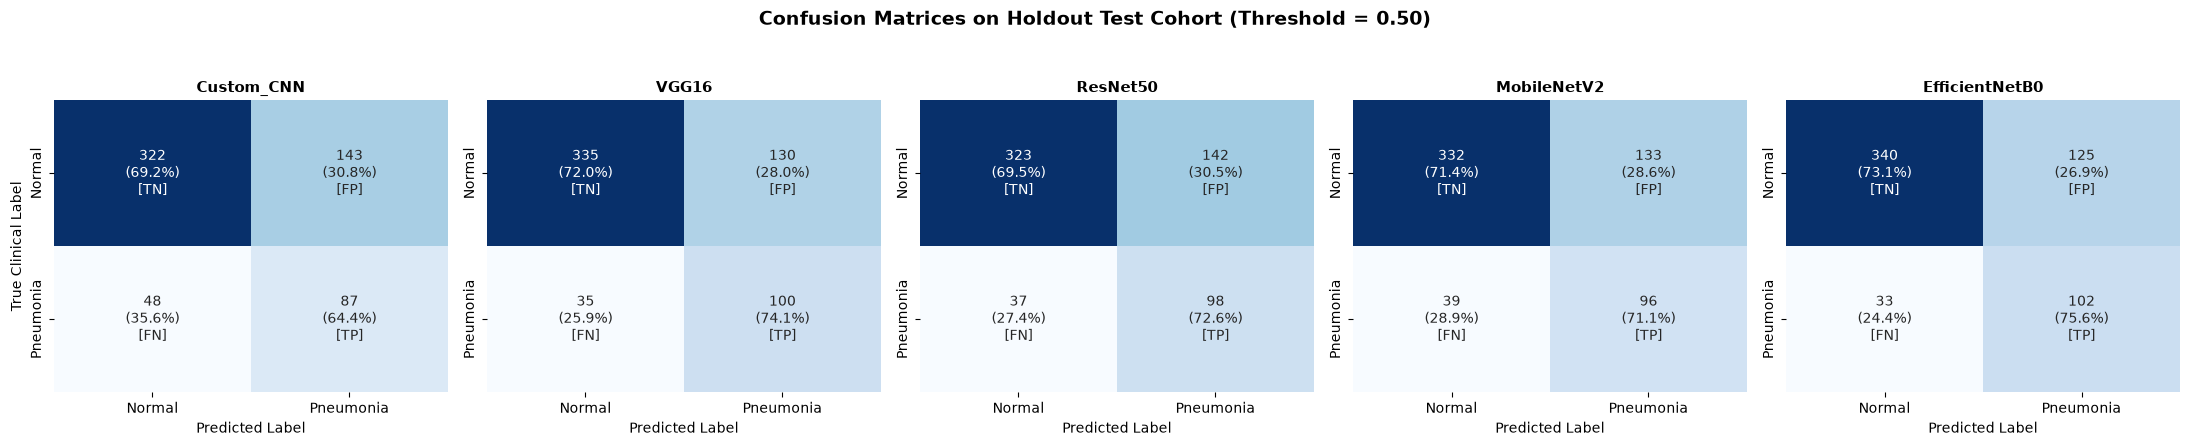

In [21]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.2))

for idx, (name, _) in enumerate(MODEL_OBJECTS.items()):
    probs = TEST_PREDICTIONS[name]
    preds = (probs >= 0.50).astype(int)
    cm = confusion_matrix(y_test_true, preds, labels=[0, 1])
    cm_norm = cm.astype("float") / np.maximum(cm.sum(axis=1)[:, np.newaxis], 1)

    annot = np.array([
        [f"{cm[0,0]}\n({cm_norm[0,0]:.1%})\n[TN]", f"{cm[0,1]}\n({cm_norm[0,1]:.1%})\n[FP]"],
        [f"{cm[1,0]}\n({cm_norm[1,0]:.1%})\n[FN]", f"{cm[1,1]}\n({cm_norm[1,1]:.1%})\n[TP]"],
    ])

    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", ax=axes[idx], cbar=False,
                xticklabels=["Normal", "Pneumonia"], yticklabels=["Normal", "Pneumonia"])
    axes[idx].set_title(f"{name}", fontsize=11, fontweight="bold")
    axes[idx].set_xlabel("Predicted Label", fontsize=10)
    axes[idx].set_ylabel("True Clinical Label" if idx == 0 else "", fontsize=10)

plt.suptitle("Confusion Matrices on Holdout Test Cohort (Threshold = 0.50)", fontsize=14, fontweight="bold", y=1.05)
plt.tight_layout()
plt.show()

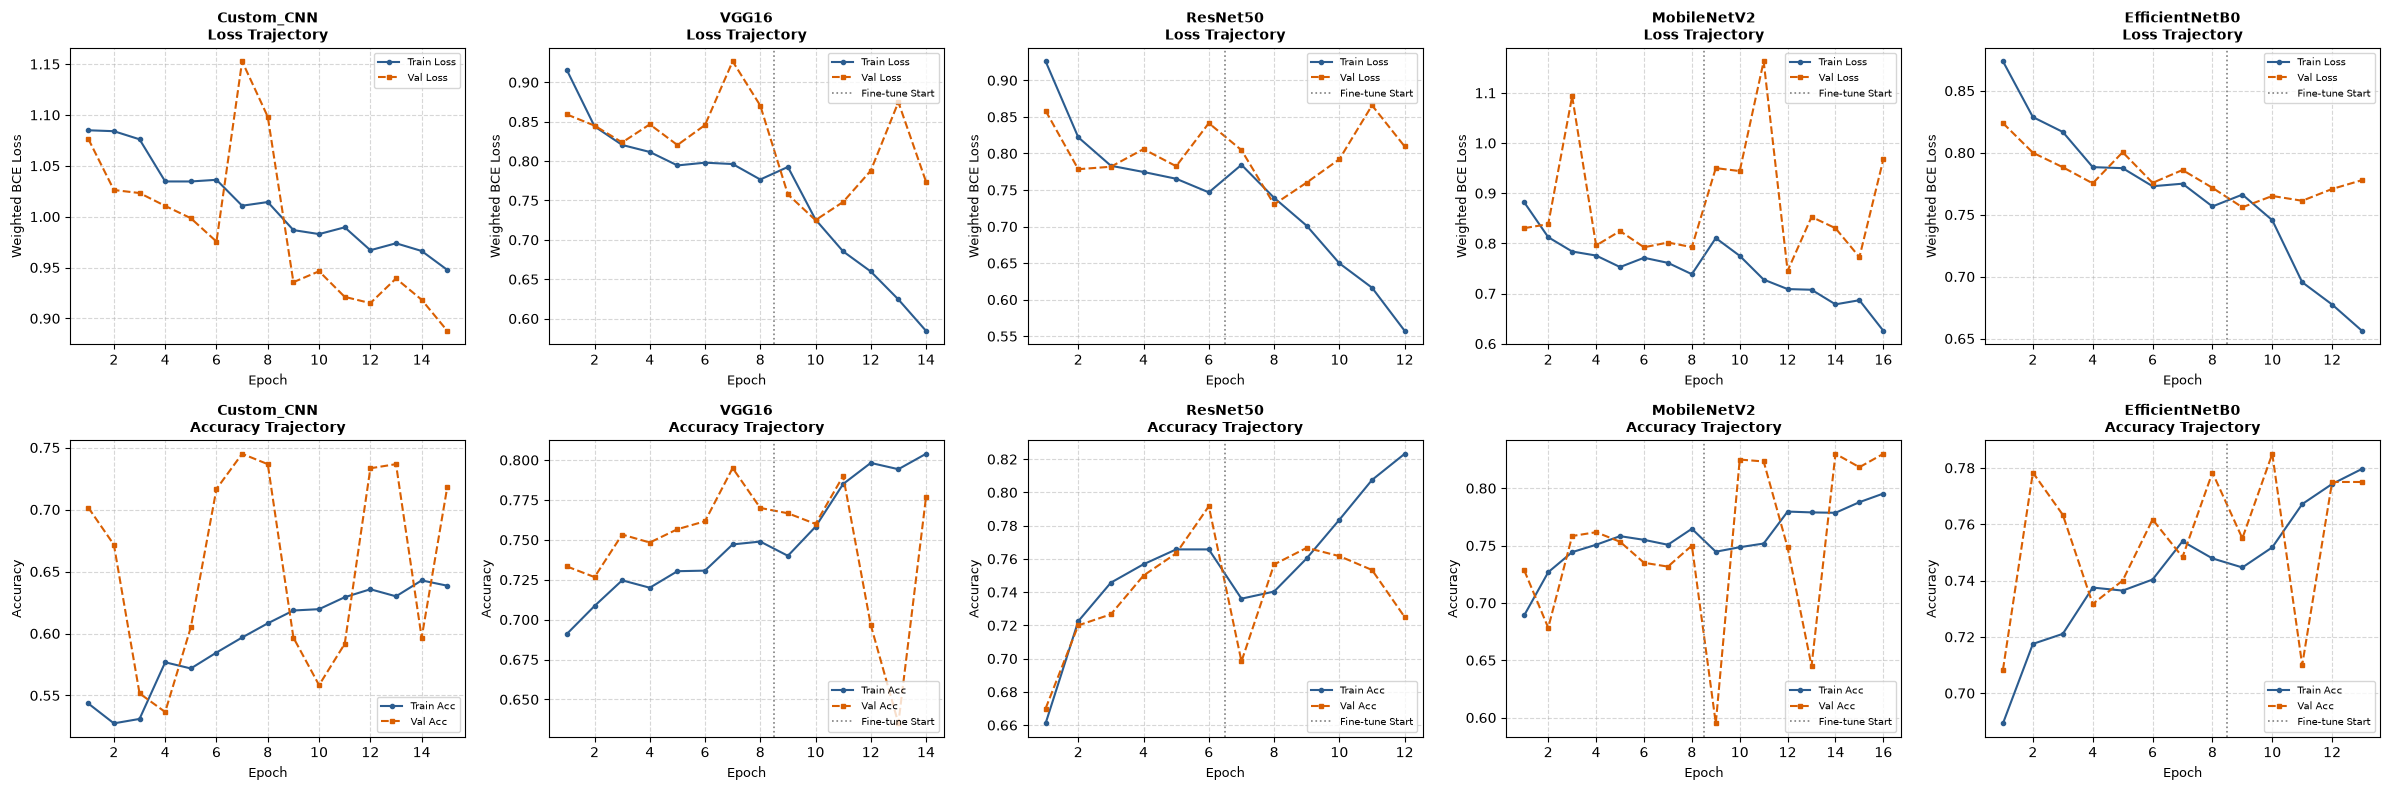

In [22]:
fig, axes = plt.subplots(2, 5, figsize=(24, 8))

for idx, (name, hist) in enumerate(TRAINING_HISTORIES.items()):
    epochs_range = range(1, len(hist["loss"]) + 1)
    s1_end = hist.get("stage1_epochs", 0)

    axes[0, idx].plot(epochs_range, hist["loss"], "o-", color="#2b5c8f", label="Train Loss", lw=1.5, ms=3)
    axes[0, idx].plot(epochs_range, hist["val_loss"], "s--", color="#d95f02", label="Val Loss", lw=1.5, ms=3)
    if name != "Custom_CNN" and 0 < s1_end < len(hist["loss"]):
        axes[0, idx].axvline(s1_end + 0.5, color="gray", linestyle=":", lw=1.2, label="Fine-tune Start")
    axes[0, idx].set_title(f"{name}\nLoss Trajectory", fontsize=10, fontweight="bold")
    axes[0, idx].set_xlabel("Epoch", fontsize=9)
    axes[0, idx].set_ylabel("Weighted BCE Loss", fontsize=9)
    axes[0, idx].grid(True, linestyle="--", alpha=0.5)
    axes[0, idx].legend(loc="upper right", fontsize=7.5)

    axes[1, idx].plot(epochs_range, hist["accuracy"], "o-", color="#2b5c8f", label="Train Acc", lw=1.5, ms=3)
    axes[1, idx].plot(epochs_range, hist["val_accuracy"], "s--", color="#d95f02", label="Val Acc", lw=1.5, ms=3)
    if name != "Custom_CNN" and 0 < s1_end < len(hist["loss"]):
        axes[1, idx].axvline(s1_end + 0.5, color="gray", linestyle=":", lw=1.2, label="Fine-tune Start")
    axes[1, idx].set_title(f"{name}\nAccuracy Trajectory", fontsize=10, fontweight="bold")
    axes[1, idx].set_xlabel("Epoch", fontsize=9)
    axes[1, idx].set_ylabel("Accuracy", fontsize=9)
    axes[1, idx].grid(True, linestyle="--", alpha=0.5)
    axes[1, idx].legend(loc="lower right", fontsize=7.5)

plt.tight_layout()
plt.show()

---
## 18. Multi-Model ROC and Precision-Recall Curves

In medical diagnostic screening, the **Receiver Operating Characteristic (ROC)** curve and the **Precision-Recall (PR)** curve provide threshold-independent visual assessments of discriminative power:
- **ROC Curve**: Illustrates the trade-off between Sensitivity (True Positive Rate) and $1 - \text{Specificity}$ (False Positive Rate) across all possible decision thresholds $\tau \in [0, 1]$.
- **Precision-Recall (PR) Curve**: In imbalanced medical cohorts, the PR curve is significantly more informative than ROC because it focuses directly on the minority positive class without being inflated by true negative counts.
- **Probability Distributions**: Visualizes the separation between predicted probabilities for Normal vs Pneumonia cases.

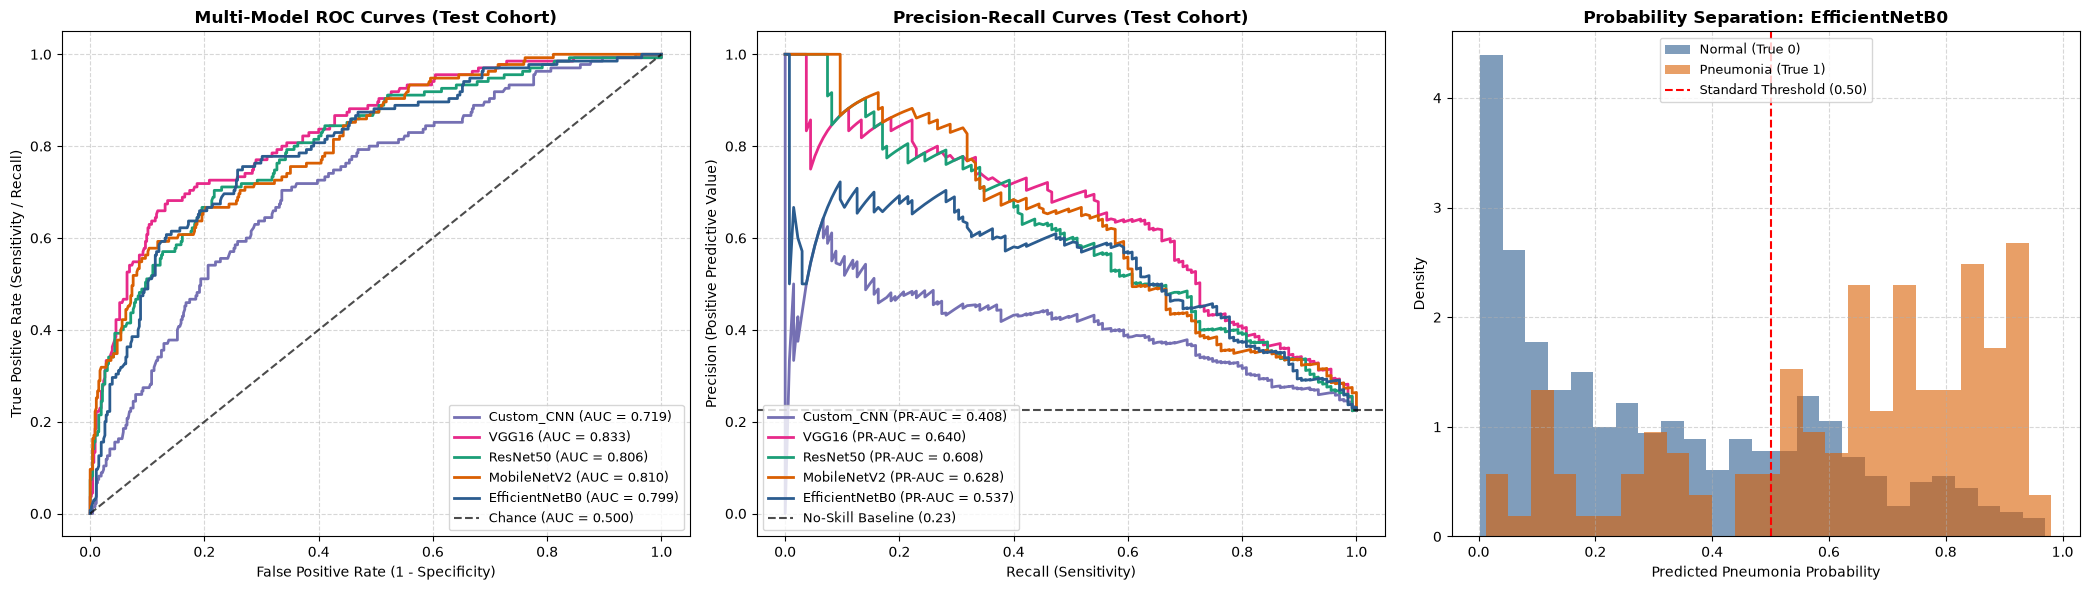

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
colors = {
    "Custom_CNN": "#7570b3",
    "VGG16": "#e7298a",
    "ResNet50": "#1b9e77",
    "MobileNetV2": "#d95f02",
    "EfficientNetB0": "#2b5c8f",
}

for name, probs in TEST_PREDICTIONS.items():
    fpr_arr, tpr_arr, _ = roc_curve(y_test_true, probs)
    auc_val = roc_auc_score(y_test_true, probs)
    axes[0].plot(fpr_arr, tpr_arr, lw=2, color=colors[name], label=f"{name} (AUC = {auc_val:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1.5, alpha=0.7, label="Chance (AUC = 0.500)")
axes[0].set_title("Multi-Model ROC Curves (Test Cohort)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=10)
axes[0].set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=10)
axes[0].legend(loc="lower right", fontsize=9)
axes[0].grid(True, linestyle="--", alpha=0.5)

baseline_prevalence = np.mean(y_test_true)
for name, probs in TEST_PREDICTIONS.items():
    prec_arr, rec_arr, _ = precision_recall_curve(y_test_true, probs)
    pr_auc_val = average_precision_score(y_test_true, probs)
    axes[1].plot(rec_arr, prec_arr, lw=2, color=colors[name], label=f"{name} (PR-AUC = {pr_auc_val:.3f})")

axes[1].axhline(y=baseline_prevalence, color="k", linestyle="--", lw=1.5, alpha=0.7, label=f"No-Skill Baseline ({baseline_prevalence:.2f})")
axes[1].set_title("Precision-Recall Curves (Test Cohort)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Recall (Sensitivity)", fontsize=10)
axes[1].set_ylabel("Precision (Positive Predictive Value)", fontsize=10)
axes[1].legend(loc="lower left", fontsize=9)
axes[1].grid(True, linestyle="--", alpha=0.5)

best_f1_model_name = max(EVALUATION_RESULTS, key=lambda x: x["F1 Score"])["Model Name"]
best_f1_probs = TEST_PREDICTIONS[best_f1_model_name]

axes[2].hist(best_f1_probs[y_test_true == 0], bins=25, alpha=0.6, color="#2b5c8f", density=True, label="Normal (True 0)")
axes[2].hist(best_f1_probs[y_test_true == 1], bins=25, alpha=0.6, color="#d95f02", density=True, label="Pneumonia (True 1)")
axes[2].axvline(x=0.50, color="red", linestyle="--", lw=1.5, label="Standard Threshold (0.50)")
axes[2].set_title(f"Probability Separation: {best_f1_model_name}", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Predicted Pneumonia Probability", fontsize=10)
axes[2].set_ylabel("Density", fontsize=10)
axes[2].legend(loc="upper center", fontsize=9)
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

---
## 19. Consolidated Model Comparison & Clinical Selection Strategy

In this section, we compile all quantitative metrics across the five architectures into a master comparison table and multi-panel diagnostic visualization.

### 19.1 The Clinical Screening Asymmetry: Sensitivity vs Specificity
In medical triage, errors are fundamentally asymmetric:
- **False Negative (Missed Pneumonia)**: Catastrophic clinical outcome. An undetected patient with active bacterial consolidation discharged from emergency triage is at imminent risk of respiratory failure, sepsis, and death.
- **False Positive (False Alarm)**: Moderate clinical cost. A false alarm prompts secondary confirmatory evaluation, such as high-resolution thoracic CT, auscultation, or empirical microbiological workup.

Therefore, for frontline screening CAD systems, model selection **strictly prioritizes Sensitivity (Recall), PR-AUC, and F1-Score / Balanced Accuracy** rather than raw overall accuracy alone.

MASTER ARCHITECTURAL COMPARISON (HOLDOUT TEST COHORT):
    Model Name  Accuracy  Recall (Sensitivity)  Specificity  Precision  F1 Score  ROC-AUC  PR-AUC    MCC  Balanced Accuracy  Clinical_Composite_Score  Training Time (s)  Total Parameters  Inference Latency (ms)
         VGG16    0.7250                0.7407       0.7204     0.4348    0.5479   0.8328  0.6398 0.3961             0.7306                    0.6709           228.7968          14863041                  3.9473
EfficientNetB0    0.7367                0.7556       0.7312     0.4493    0.5635   0.7993  0.5368 0.4191             0.7434                    0.6503           159.4439           4174205                  7.3451
   MobileNetV2    0.7133                0.7111       0.7140     0.4192    0.5275   0.8098  0.6280 0.3654             0.7125                    0.6496           180.3202           2388225                  5.1193
      ResNet50    0.7017                0.7259       0.6946     0.4083    0.5227   0.8057  0.6079 0.3

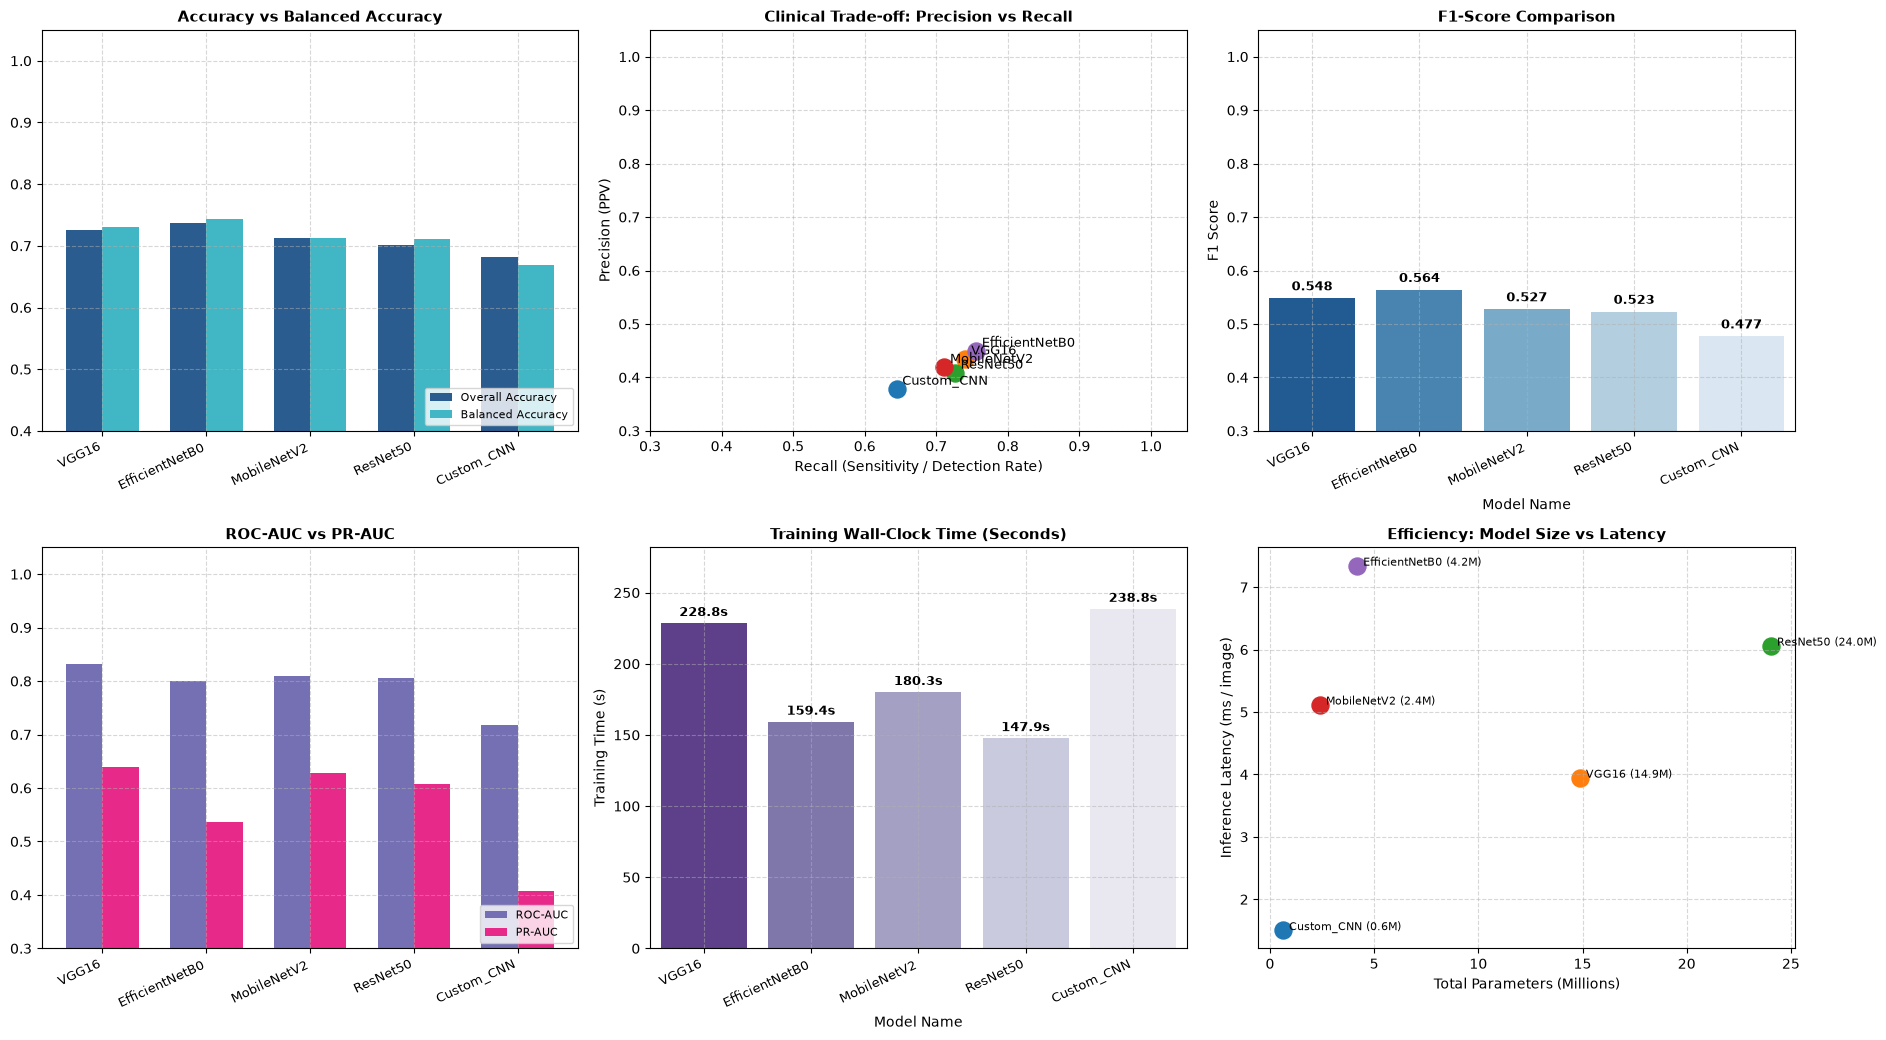


[SELECTION] Optimal Architecture Selected: VGG16
Selection Rationale: Achieves maximal Clinical Composite Score (0.6709) with Sensitivity=0.7407, PR-AUC=0.6398, F1=0.5479, ROC-AUC=0.8328.


In [24]:
df_comparison = pd.DataFrame(EVALUATION_RESULTS)
df_comparison["Clinical_Composite_Score"] = (
    0.40 * df_comparison["Recall (Sensitivity)"]
    + 0.30 * df_comparison["PR-AUC"]
    + 0.20 * df_comparison["F1 Score"]
    + 0.10 * df_comparison["Balanced Accuracy"]
)

cols_display = [
    "Model Name", "Accuracy", "Recall (Sensitivity)", "Specificity",
    "Precision", "F1 Score", "ROC-AUC", "PR-AUC", "MCC",
    "Balanced Accuracy", "Clinical_Composite_Score",
    "Training Time (s)", "Total Parameters", "Inference Latency (ms)"
]
df_comparison_display = df_comparison[cols_display].sort_values(by="Clinical_Composite_Score", ascending=False).reset_index(drop=True)

print("=" * 125)
print("MASTER ARCHITECTURAL COMPARISON (HOLDOUT TEST COHORT):")
print("=" * 125)
print(df_comparison_display.round(4).to_string(index=False))
print("=" * 125)

fig, axes = plt.subplots(2, 3, figsize=(19, 10.5))

x_idx = np.arange(len(df_comparison_display))
width = 0.35

# 1. Accuracy vs Balanced Accuracy
axes[0, 0].bar(x_idx - width / 2, df_comparison_display["Accuracy"], width, label="Overall Accuracy", color="#2b5c8f")
axes[0, 0].bar(x_idx + width / 2, df_comparison_display["Balanced Accuracy"], width, label="Balanced Accuracy", color="#41b6c4")
axes[0, 0].set_xticks(x_idx)
axes[0, 0].set_xticklabels(df_comparison_display["Model Name"], rotation=25, ha="right", fontsize=9)
axes[0, 0].set_title("Accuracy vs Balanced Accuracy", fontsize=11, fontweight="bold")
axes[0, 0].set_ylim([0.4, 1.05])
axes[0, 0].legend(loc="lower right", fontsize=8)
axes[0, 0].grid(True, linestyle="--", alpha=0.5)

# 2. Precision vs Recall Scatter
for _, row in df_comparison.iterrows():
    axes[0, 1].scatter(row["Recall (Sensitivity)"], row["Precision"], s=150, label=row["Model Name"])
    axes[0, 1].annotate(row["Model Name"], (row["Recall (Sensitivity)"] + 0.008, row["Precision"] + 0.008), fontsize=9)
axes[0, 1].set_xlabel("Recall (Sensitivity / Detection Rate)", fontsize=10)
axes[0, 1].set_ylabel("Precision (PPV)", fontsize=10)
axes[0, 1].set_title("Clinical Trade-off: Precision vs Recall", fontsize=11, fontweight="bold")
axes[0, 1].set_xlim([0.3, 1.05])
axes[0, 1].set_ylim([0.3, 1.05])
axes[0, 1].grid(True, linestyle="--", alpha=0.5)

# 3. F1-Score Comparison
sns.barplot(data=df_comparison_display, x="Model Name", y="F1 Score", hue="Model Name", palette="Blues_r", legend=False, ax=axes[0, 2])
axes[0, 2].set_title("F1-Score Comparison", fontsize=11, fontweight="bold")
axes[0, 2].set_xticks(x_idx)
axes[0, 2].set_xticklabels(df_comparison_display["Model Name"], rotation=25, ha="right", fontsize=9)
axes[0, 2].set_ylim([0.3, 1.05])
for i, v in enumerate(df_comparison_display["F1 Score"]):
    axes[0, 2].text(i, v + 0.015, f"{v:.3f}", ha="center", fontsize=9, fontweight="bold")
axes[0, 2].grid(True, linestyle="--", alpha=0.5)

# 4. ROC-AUC vs PR-AUC
axes[1, 0].bar(x_idx - width / 2, df_comparison_display["ROC-AUC"], width, label="ROC-AUC", color="#7570b3")
axes[1, 0].bar(x_idx + width / 2, df_comparison_display["PR-AUC"], width, label="PR-AUC", color="#e7298a")
axes[1, 0].set_xticks(x_idx)
axes[1, 0].set_xticklabels(df_comparison_display["Model Name"], rotation=25, ha="right", fontsize=9)
axes[1, 0].set_title("ROC-AUC vs PR-AUC", fontsize=11, fontweight="bold")
axes[1, 0].set_ylim([0.3, 1.05])
axes[1, 0].legend(loc="lower right", fontsize=8)
axes[1, 0].grid(True, linestyle="--", alpha=0.5)

# 5. Training Wall-Clock Time
sns.barplot(data=df_comparison_display, x="Model Name", y="Training Time (s)", hue="Model Name", palette="Purples_r", legend=False, ax=axes[1, 1])
axes[1, 1].set_title("Training Wall-Clock Time (Seconds)", fontsize=11, fontweight="bold")
axes[1, 1].set_xticks(x_idx)
axes[1, 1].set_xticklabels(df_comparison_display["Model Name"], rotation=25, ha="right", fontsize=9)
max_t = df_comparison_display["Training Time (s)"].max()
axes[1, 1].set_ylim([0, max_t * 1.18])
for i, v in enumerate(df_comparison_display["Training Time (s)"]):
    axes[1, 1].text(i, v + max_t * 0.02, f"{v:.1f}s", ha="center", fontsize=9, fontweight="bold")
axes[1, 1].grid(True, linestyle="--", alpha=0.5)

# 6. Parameter Size vs Inference Latency
for _, row in df_comparison.iterrows():
    param_m = row["Total Parameters"] / 1e6
    axes[1, 2].scatter(param_m, row["Inference Latency (ms)"], s=150, label=row["Model Name"])
    axes[1, 2].annotate(f"{row['Model Name']} ({param_m:.1f}M)", (param_m + 0.3, row["Inference Latency (ms)"]), fontsize=8)
axes[1, 2].set_xlabel("Total Parameters (Millions)", fontsize=10)
axes[1, 2].set_ylabel("Inference Latency (ms / image)", fontsize=10)
axes[1, 2].set_title("Efficiency: Model Size vs Latency", fontsize=11, fontweight="bold")
axes[1, 2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

best_arch_record = df_comparison.sort_values(by="Clinical_Composite_Score", ascending=False).iloc[0]
BEST_MODEL_NAME = best_arch_record["Model Name"]
best_model = MODEL_OBJECTS[BEST_MODEL_NAME]

print(f"\n[SELECTION] Optimal Architecture Selected: {BEST_MODEL_NAME}")
print(
    f"Selection Rationale: Achieves maximal Clinical Composite Score ({best_arch_record['Clinical_Composite_Score']:.4f}) "
    f"with Sensitivity={best_arch_record['Recall (Sensitivity)']:.4f}, PR-AUC={best_arch_record['PR-AUC']:.4f}, "
    f"F1={best_arch_record['F1 Score']:.4f}, ROC-AUC={best_arch_record['ROC-AUC']:.4f}."
)

---
## 20. Detailed Error Analysis of the Optimal Architecture

To move beyond aggregate summary statistics, we perform an exhaustive error audit of the selected top-performing model on the holdout test cohort.

### 20.1 Radiological Taxonomy of Failure Modes
1. **False Positives (FP - Non-pneumonia misclassified as Pneumonia)**:
   - **Cardiomegaly & Vascular Crowding**: Enlarged cardiac silhouettes or pulmonary venous hypertension crowd lung bases, mimicking focal consolidation.
   - **Basilar Atelectasis & Pleural Thickening**: Dependent alveolar collapse (often from shallow inspiration) produces linear radio-opacities resembling early bronchopneumonia.
   - **Superimposed Bone Artifacts**: Overlapping ribs, scapulae, or osteophytes mimicking nodular infiltrates.
2. **False Negatives (FN - True Pneumonia missed by Model)**:
   - **Faint Retrocardiac Opacities**: Consolidation residing in the left lower lobe directly behind the dense cardiac silhouette, where contrast attenuation is low.
   - **Early Interstitial Infiltrates**: Viral or atypical mycoplasma pneumonias presenting with delicate reticular or ground-glass opacities rather than dense lobar consolidation.
   - **Diaphragmatic Blunting**: Small basilar consolidations obscured by the curvature of the costophrenic angles.

Test Cohort Categorization for VGG16:
  - True Positives  (TP) : 100 (Pneumonia correctly flagged)
  - True Negatives  (TN) : 335 (Normal correctly cleared)
  - False Positives (FP) : 130 (False alarms / misclassified normal)
  - False Negatives (FN) :  35 (Missed pneumonia cases - CRITICAL)


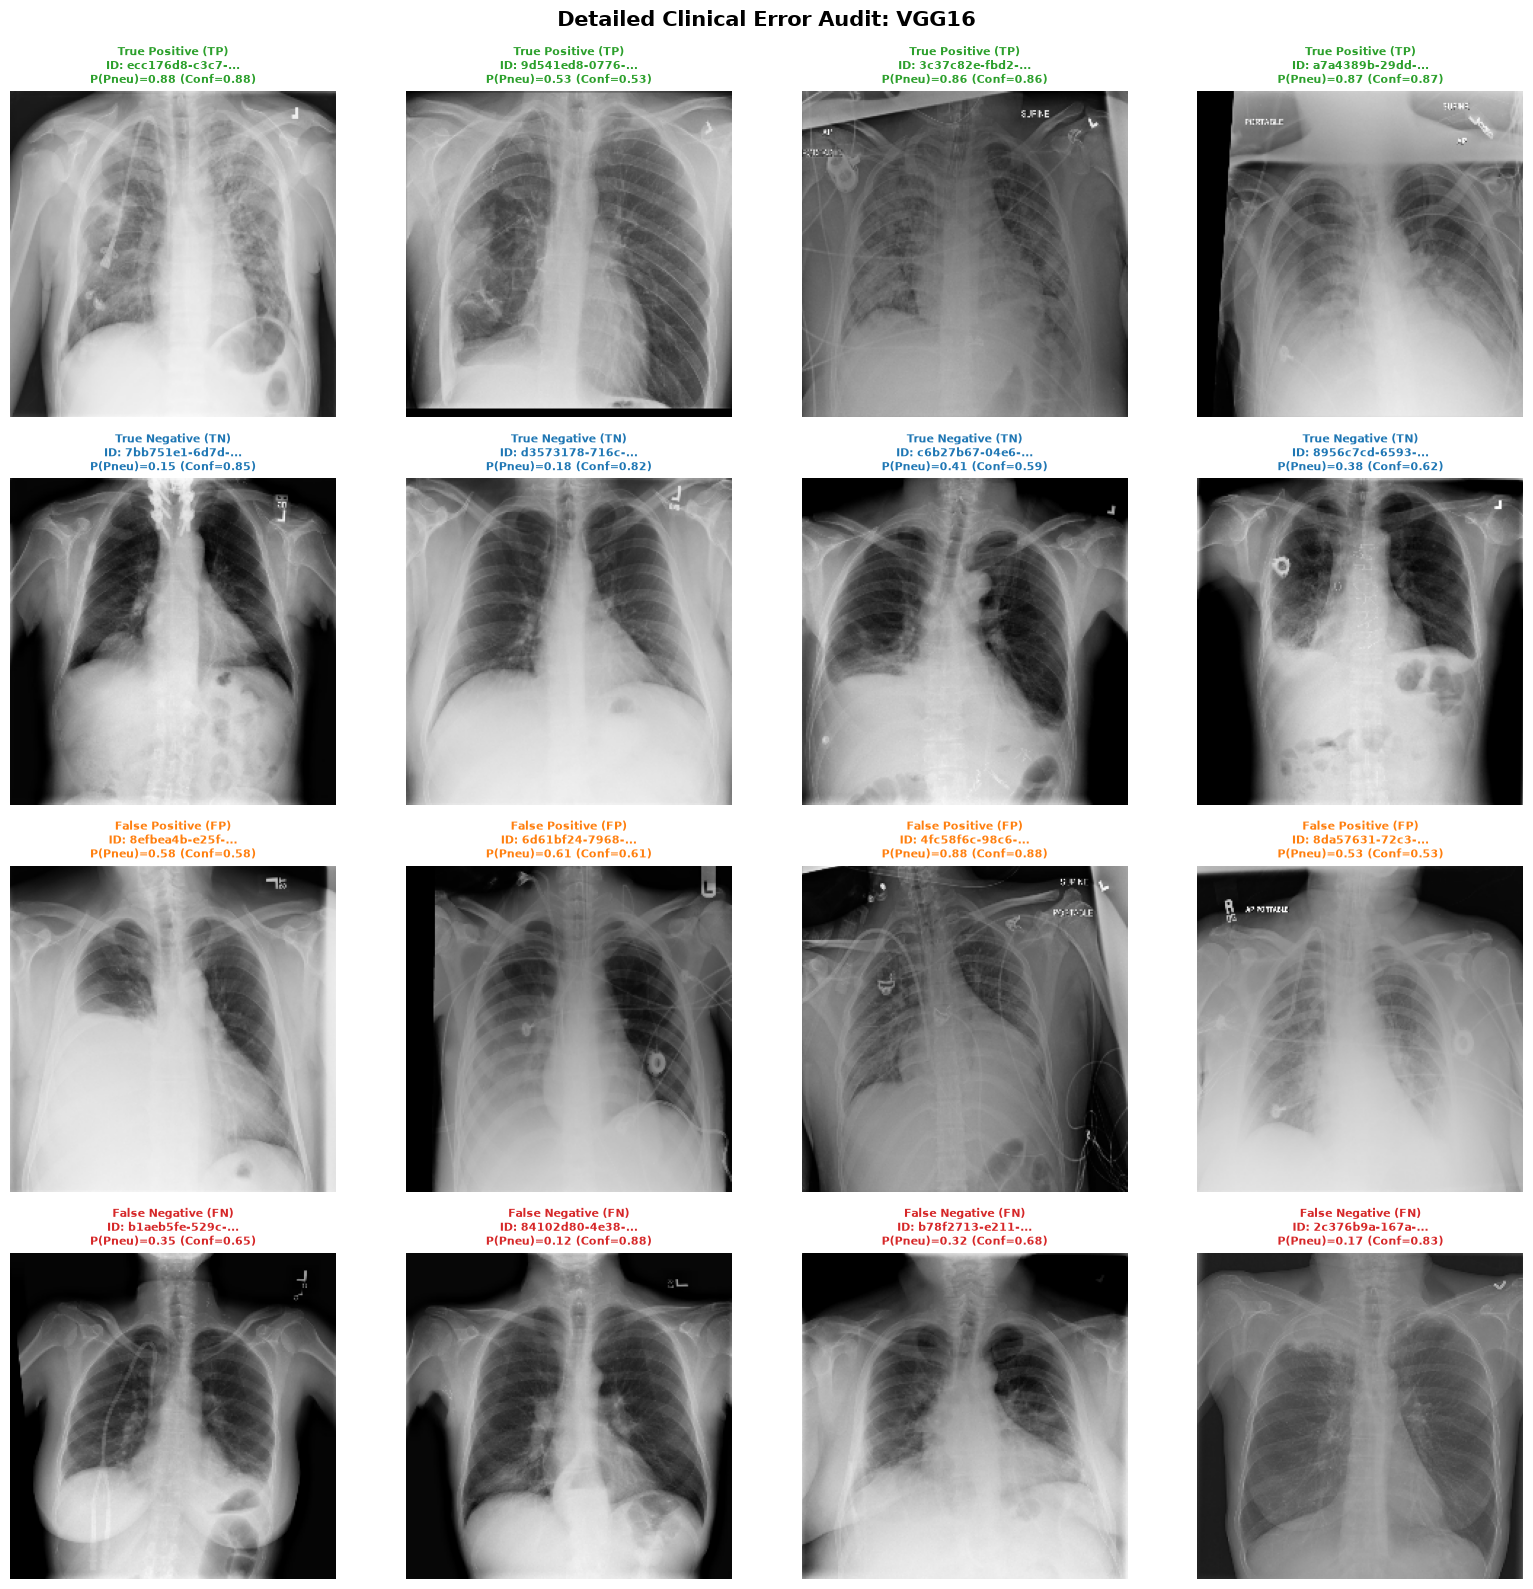

In [25]:
best_probs = TEST_PREDICTIONS[BEST_MODEL_NAME]
best_preds = (best_probs >= 0.50).astype(int)

tp_indices = np.where((y_test_true == 1) & (best_preds == 1))[0]
tn_indices = np.where((y_test_true == 0) & (best_preds == 0))[0]
fp_indices = np.where((y_test_true == 0) & (best_preds == 1))[0]
fn_indices = np.where((y_test_true == 1) & (best_preds == 0))[0]

print(f"Test Cohort Categorization for {BEST_MODEL_NAME}:")
print(f"  - True Positives  (TP) : {len(tp_indices):3d} (Pneumonia correctly flagged)")
print(f"  - True Negatives  (TN) : {len(tn_indices):3d} (Normal correctly cleared)")
print(f"  - False Positives (FP) : {len(fp_indices):3d} (False alarms / misclassified normal)")
print(f"  - False Negatives (FN) : {len(fn_indices):3d} (Missed pneumonia cases - CRITICAL)")

categories = [
    ("True Positive (TP)", tp_indices, "#2ca02c"),
    ("True Negative (TN)", tn_indices, "#1f77b4"),
    ("False Positive (FP)", fp_indices, "#ff7f0e"),
    ("False Negative (FN)", fn_indices, "#d62728"),
]

fig, axes = plt.subplots(4, 4, figsize=(16, 16))
for row_idx, (cat_name, cat_idx_list, color) in enumerate(categories):
    sample_sub_indices = cat_idx_list[:4]
    for col_idx in range(4):
        ax = axes[row_idx, col_idx]
        if col_idx < len(sample_sub_indices):
            s_idx = sample_sub_indices[col_idx]
            img_path = test_df["image_path"].iloc[s_idx]
            pid = test_df["patientId"].iloc[s_idx]
            prob = best_probs[s_idx]
            conf = prob if best_preds[s_idx] == 1 else (1.0 - prob)
            img_rgb = load_and_preprocess_single_image(img_path, IMG_SIZE)
            ax.imshow(img_rgb)
            ax.set_title(f"{cat_name}\nID: {pid[:14]}...\nP(Pneu)={prob:.2f} (Conf={conf:.2f})", fontsize=8, fontweight="bold", color=color)
        elif col_idx == 0 and len(sample_sub_indices) == 0:
            ax.text(0.5, 0.5, f"No {cat_name}\nobserved", ha="center", va="center", fontsize=10, color=color)
        ax.axis("off")

plt.suptitle(f"Detailed Clinical Error Audit: {BEST_MODEL_NAME}", fontsize=15, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()

---
## 21. Model Interpretability & Explainable AI (Grad-CAM)

Deep neural networks deployed in clinical medicine cannot function as inscrutable "black boxes." Explainability is required to verify that the network's predictive decisions stem from genuine pulmonary pathology rather than extraneous confounding features (such as radiology marker letters 'L'/'R', thoracic cables, or ventilator tubing).

### 21.1 Mathematical Formulation of Grad-CAM
Gradient-weighted Class Activation Mapping (Grad-CAM) utilizes the gradient flow of the target concept logit $y^c$ (prior to sigmoid activation) with respect to feature activation map $A^k$ of the final convolutional layer across all five architectures (`Custom_CNN`, `VGG16`, `ResNet50`, `MobileNetV2`, `EfficientNetB0`):
1. **Neuron Importance Weights ($\alpha_k^c$)**: Computed via global average pooling of gradients over spatial dimensions width $u$ and height $v$:
   $$\alpha_k^c = \frac{1}{Z} \sum_i \sum_j \frac{\partial y^c}{\partial A_{ij}^k}$$
2. **Localization Map ($L_{\text{Grad-CAM}}^c$)**: Weighted linear combination of forward activation maps followed by Rectified Linear Unit (ReLU) to focus exclusively on features that positively contribute to the target class:
   $$L_{\text{Grad-CAM}}^c = \text{ReLU}\left(\sum_k \alpha_k^c A^k\right)$$
3. **Superimposition**: The coarse 2D heatmap is upsampled to input image dimensions $(224 \times 224)$, normalized to $[0, 1]$, color-mapped with Jet, and blended with the original radiograph via alpha blending.

> [!NOTE] **Scientific Caveat on Explainable AI**
> Grad-CAM visualizes gradient saliency and feature attribution within the convolutional receptive fields. It **does NOT** represent a histopathological ground truth or prove definitive clinical reasoning.

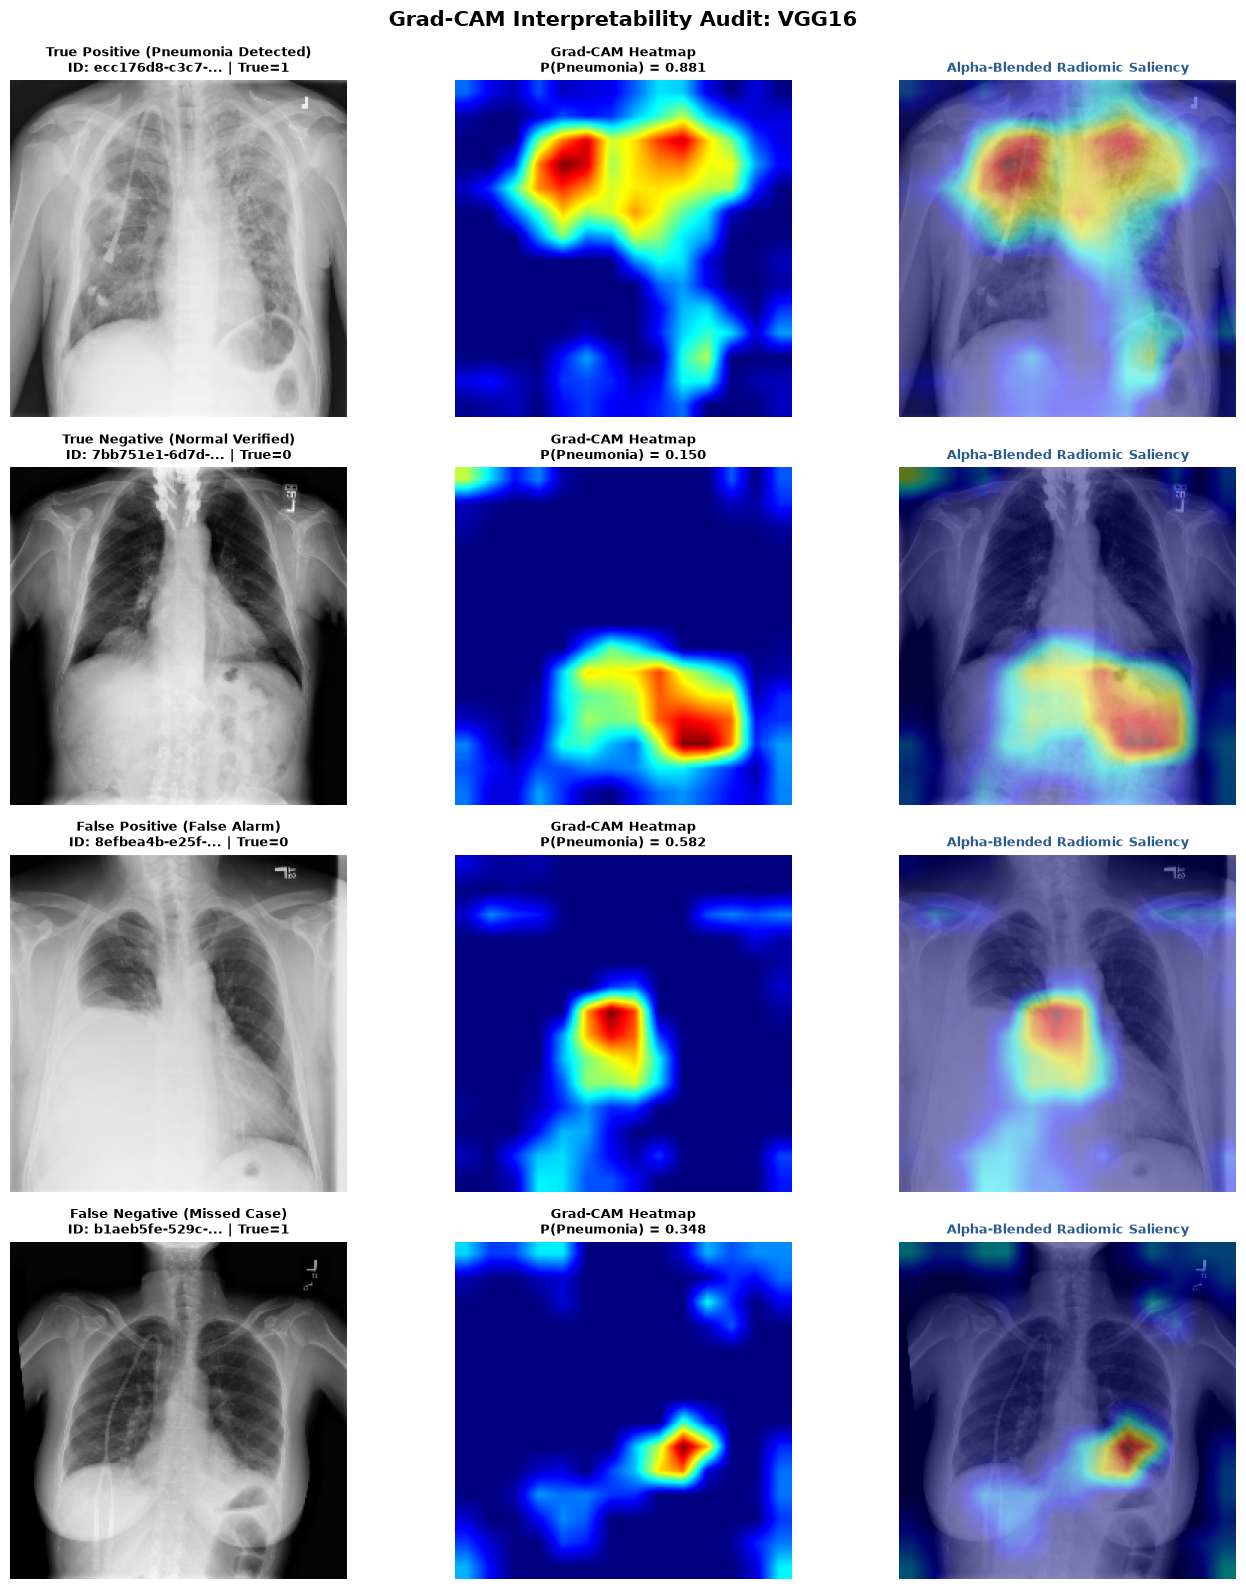

In [26]:
def generate_gradcam_heatmap(model, img_tensor_1chw):
    """Generate Grad-CAM activation heatmap for any of the 5 PyTorch architectures."""
    model.eval()
    target_layer = model.get_gradcam_target_layer()
    activations, gradients = {}, {}
    tensor_hooks = []

    # Temporarily disable inplace activations so tensor hooks remain safe under autograd
    toggled_inplace = []
    for m in model.modules():
        if getattr(m, "inplace", False):
            m.inplace = False
            toggled_inplace.append(m)

    def forward_hook(module, inp, out):
        activations["value"] = out.detach()
        if out.requires_grad:
            tensor_hooks.append(out.register_hook(lambda grad: gradients.__setitem__("value", grad.detach())))

    h_fwd = target_layer.register_forward_hook(forward_hook)

    try:
        x = img_tensor_1chw.to(DEVICE).float().detach().requires_grad_(True)
        model.zero_grad(set_to_none=True)
        with torch.amp.autocast(device_type=DEVICE.type, enabled=False):
            with torch.enable_grad():
                logit = model(x).view(-1)[0]
                logit.backward()

        acts = activations["value"]
        grads = gradients["value"]
        weights = grads.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((weights * acts).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=(IMG_HEIGHT, IMG_WIDTH), mode="bilinear", align_corners=False)
        cam_np = cam[0, 0].detach().cpu().numpy()
        cam_np = (cam_np - cam_np.min()) / (cam_np.max() - cam_np.min() + 1e-8)
        prob = float(torch.sigmoid(logit.detach()).cpu().item())
        return cam_np, prob
    finally:
        h_fwd.remove()
        for h in tensor_hooks:
            h.remove()
        for m in toggled_inplace:
            m.inplace = True

def overlay_gradcam(original_img_rgb, heatmap, alpha=0.45):
    """Blend normalized heatmap with original radiograph using Jet colormap."""
    heatmap_uint8 = np.uint8(255 * np.clip(heatmap, 0.0, 1.0))
    heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    superimposed = np.uint8(np.clip(original_img_rgb * (1.0 - alpha) + heatmap_color * alpha, 0, 255))
    return heatmap_color, superimposed

# Safely pick representative TP, TN, FP, FN (or boundary cases if any category is empty)
tp_pick = int(tp_indices[0]) if len(tp_indices) > 0 else int(np.where(y_test_true == 1)[0][np.argmax(best_probs[y_test_true == 1])])
tn_pick = int(tn_indices[0]) if len(tn_indices) > 0 else int(np.where(y_test_true == 0)[0][np.argmin(best_probs[y_test_true == 0])])
fp_label = "False Positive (False Alarm)" if len(fp_indices) > 0 else "Borderline Normal (Highest P)"
fp_pick = int(fp_indices[0]) if len(fp_indices) > 0 else int(np.where(y_test_true == 0)[0][np.argmax(best_probs[y_test_true == 0])])
fn_label = "False Negative (Missed Case)" if len(fn_indices) > 0 else "Borderline Pneumonia (Lowest P)"
fn_pick = int(fn_indices[0]) if len(fn_indices) > 0 else int(np.where(y_test_true == 1)[0][np.argmin(best_probs[y_test_true == 1])])

demo_audit_indices = [
    ("True Positive (Pneumonia Detected)", tp_pick),
    ("True Negative (Normal Verified)", tn_pick),
    (fp_label, fp_pick),
    (fn_label, fn_pick),
]

fig, axes = plt.subplots(4, 3, figsize=(14, 16))
for row_idx, (audit_title, test_idx) in enumerate(demo_audit_indices):
    img_path = test_df["image_path"].iloc[test_idx]
    pid = test_df["patientId"].iloc[test_idx]
    true_lbl = int(test_df["label"].iloc[test_idx])

    raw_rgb = load_and_preprocess_single_image(img_path, IMG_SIZE)
    img_tensor = transforms.ToTensor()(Image.fromarray(raw_rgb)).unsqueeze(0)

    heatmap, pred_prob = generate_gradcam_heatmap(best_model, img_tensor)
    color_map, overlay = overlay_gradcam(raw_rgb, heatmap, alpha=0.45)

    axes[row_idx, 0].imshow(raw_rgb)
    axes[row_idx, 0].set_title(f"{audit_title}\nID: {pid[:14]}... | True={true_lbl}", fontsize=9, fontweight="bold")
    axes[row_idx, 0].axis("off")

    axes[row_idx, 1].imshow(color_map)
    axes[row_idx, 1].set_title(f"Grad-CAM Heatmap\nP(Pneumonia) = {pred_prob:.3f}", fontsize=9, fontweight="bold")
    axes[row_idx, 1].axis("off")

    axes[row_idx, 2].imshow(overlay)
    axes[row_idx, 2].set_title("Alpha-Blended Radiomic Saliency", fontsize=9, fontweight="bold", color="#2b5c8f")
    axes[row_idx, 2].axis("off")

plt.suptitle(f"Grad-CAM Interpretability Audit: {BEST_MODEL_NAME}", fontsize=15, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()

---
## 22. Advanced Decision Threshold Analysis

In binary classification, the default decision threshold $\tau = 0.50$ is rarely optimal for medical screening applications characterized by asymmetric clinical costs and class imbalance.

### 22.1 Strict Validation-Only Threshold Tuning
To prevent data snooping and optimistic bias, **threshold tuning is performed exclusively on the Validation dataset**. The selected optimal threshold is then applied to the untouched holdout Test dataset.

We evaluate thresholds across $\tau \in [0.05, 0.95]$ with step $0.05$ and identify:
1. **Default Threshold ($\tau = 0.50$)**: Baseline standard.
2. **Optimal $F_1$ Threshold ($\tau_{F_1}^*$)**: Maximizes the harmonic mean of Precision and Recall.
3. **High-Sensitivity Clinical Screening Threshold ($\tau_{\text{sens}}^*$)**: Guarantees $\ge 90\%$ Sensitivity while maximizing Specificity to minimize missed pneumonia cases.

Validation Threshold Optimization Results for VGG16:
  - Optimal F1 Threshold        : tau = 0.50 (Val F1 = 0.5955)
  - Clinical High-Sensitivity   : tau = 0.35 (Val Sensitivity = 0.9111)


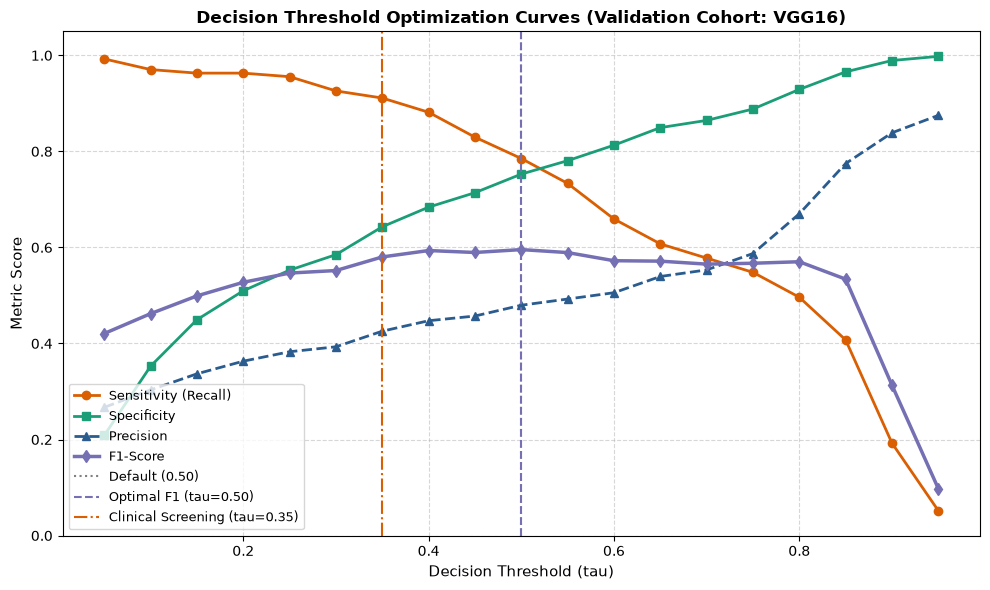


Evaluation of Tuned Operating Points on Untouched Test Cohort:
                Operating Point  Recall (Sensitivity)  Specificity  Precision  F1 Score
   Default Threshold (tau=0.50)                0.7407       0.7204     0.4348    0.5479
Optimal F1 Threshold (tau=0.50)                0.7407       0.7204     0.4348    0.5479
  Clinical Screening (tau=0.35)                0.8296       0.6000     0.3758    0.5173


In [27]:
val_probs = predict_probabilities(best_model, val_loader)
y_val_true = val_df["label"].values.astype(int)

threshold_range = np.linspace(0.05, 0.95, 19)
thresh_records = []

for th in threshold_range:
    val_preds_th = (val_probs >= th).astype(int)
    cm = confusion_matrix(y_val_true, val_preds_th, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    prec = precision_score(y_val_true, val_preds_th, zero_division=0)
    rec = recall_score(y_val_true, val_preds_th, zero_division=0)
    spec = tn / max(tn + fp, 1)
    f1 = f1_score(y_val_true, val_preds_th, zero_division=0)
    bal_acc = (rec + spec) / 2.0

    thresh_records.append({
        "Threshold": float(th),
        "Precision": float(prec),
        "Recall (Sensitivity)": float(rec),
        "Specificity": float(spec),
        "F1 Score": float(f1),
        "Balanced Accuracy": float(bal_acc),
    })

df_thresh = pd.DataFrame(thresh_records)
idx_best_f1 = df_thresh["F1 Score"].idxmax()
th_best_f1 = float(df_thresh.loc[idx_best_f1, "Threshold"])

high_sens_candidates = df_thresh[df_thresh["Recall (Sensitivity)"] >= 0.90]
if not high_sens_candidates.empty:
    th_clinical_sens = float(high_sens_candidates.sort_values(by="Specificity", ascending=False).iloc[0]["Threshold"])
else:
    th_clinical_sens = float(df_thresh.sort_values(by="Recall (Sensitivity)", ascending=False).iloc[0]["Threshold"])

print(f"Validation Threshold Optimization Results for {BEST_MODEL_NAME}:")
print(f"  - Optimal F1 Threshold        : tau = {th_best_f1:.2f} (Val F1 = {df_thresh.loc[idx_best_f1, 'F1 Score']:.4f})")
print(f"  - Clinical High-Sensitivity   : tau = {th_clinical_sens:.2f} (Val Sensitivity = {df_thresh[df_thresh['Threshold']==th_clinical_sens]['Recall (Sensitivity)'].values[0]:.4f})")

plt.figure(figsize=(10, 6))
plt.plot(df_thresh["Threshold"], df_thresh["Recall (Sensitivity)"], "o-", color="#d95f02", lw=2, label="Sensitivity (Recall)")
plt.plot(df_thresh["Threshold"], df_thresh["Specificity"], "s-", color="#1b9e77", lw=2, label="Specificity")
plt.plot(df_thresh["Threshold"], df_thresh["Precision"], "^--", color="#2b5c8f", lw=2, label="Precision")
plt.plot(df_thresh["Threshold"], df_thresh["F1 Score"], "d-", color="#7570b3", lw=2.5, label="F1-Score")

plt.axvline(x=0.50, color="gray", linestyle=":", lw=1.5, label="Default (0.50)")
plt.axvline(x=th_best_f1, color="#7570b3", linestyle="--", lw=1.5, label=f"Optimal F1 (tau={th_best_f1:.2f})")
plt.axvline(x=th_clinical_sens, color="#d95f02", linestyle="-.", lw=1.5, label=f"Clinical Screening (tau={th_clinical_sens:.2f})")

plt.title(f"Decision Threshold Optimization Curves (Validation Cohort: {BEST_MODEL_NAME})", fontsize=12, fontweight="bold")
plt.xlabel("Decision Threshold (tau)", fontsize=11)
plt.ylabel("Metric Score", fontsize=11)
plt.ylim([0.0, 1.05])
plt.legend(loc="lower left", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

test_probs_best = TEST_PREDICTIONS[BEST_MODEL_NAME]
test_preds_default = (test_probs_best >= 0.50).astype(int)
test_preds_opt = (test_probs_best >= th_best_f1).astype(int)
test_preds_sens = (test_probs_best >= th_clinical_sens).astype(int)

def summarize_threshold_performance(y_true, y_pred, label_name):
    rec = recall_score(y_true, y_pred, zero_division=0)
    spec = ((y_true == 0) & (y_pred == 0)).sum() / max((y_true == 0).sum(), 1)
    prec = precision_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    return {
        "Operating Point": label_name,
        "Recall (Sensitivity)": rec,
        "Specificity": spec,
        "Precision": prec,
        "F1 Score": f1,
    }

df_thresh_eval = pd.DataFrame([
    summarize_threshold_performance(y_test_true, test_preds_default, "Default Threshold (tau=0.50)"),
    summarize_threshold_performance(y_test_true, test_preds_opt, f"Optimal F1 Threshold (tau={th_best_f1:.2f})"),
    summarize_threshold_performance(y_test_true, test_preds_sens, f"Clinical Screening (tau={th_clinical_sens:.2f})"),
])

print("\nEvaluation of Tuned Operating Points on Untouched Test Cohort:")
print(df_thresh_eval.round(4).to_string(index=False))

---
## 23. Probability Calibration & Reliability Analysis

In clinical triage, raw neural network outputs should ideally represent calibrated probabilities: an output of $0.80$ should imply that $80\%$ of such patients truly have pneumonia.

Modern deep convolutional networks trained with class-imbalance positive weighting often shift probability estimates upward relative to empirical prevalence.

### 23.1 Quantitative Calibration Metrics
1. **Brier Score**: Mean squared error between predicted probability $p_i$ and true binary label $y_i$:
   $$\text{BS} = \frac{1}{N} \sum_{i=1}^N (p_i - y_i)^2$$
   A lower Brier score indicates superior probabilistic calibration (with $0.0$ being perfect).
2. **Reliability Diagram**: Plots empirical fraction of true positives against mean predicted probability across 10 decile bins. Perfect calibration coincides with the $45^\circ$ diagonal.

Calibration Metrics for VGG16 on Test Cohort:
  - Brier Score Loss           : 0.1731 (Benchmark: closer to 0 is superior)
  - Expected Calibration Error : 0.1811 (18.11%)


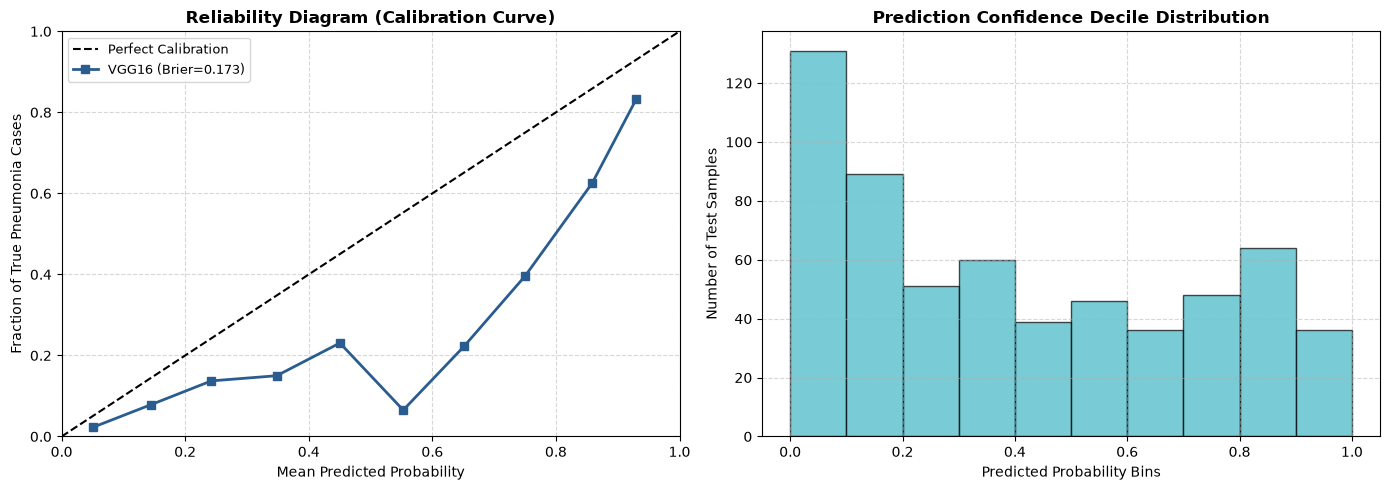

In [28]:
prob_true, prob_pred = calibration_curve(y_test_true, test_probs_best, n_bins=10, strategy="uniform")
brier_score = float(brier_score_loss(y_test_true, test_probs_best))

bin_edges = np.linspace(0.0, 1.0, 11)
ece = 0.0
for i in range(10):
    if i < 9:
        bin_mask = (test_probs_best >= bin_edges[i]) & (test_probs_best < bin_edges[i + 1])
    else:
        bin_mask = (test_probs_best >= bin_edges[i]) & (test_probs_best <= bin_edges[i + 1])
    bin_size = int(np.sum(bin_mask))
    if bin_size > 0:
        bin_acc = float(np.mean(y_test_true[bin_mask]))
        bin_conf = float(np.mean(test_probs_best[bin_mask]))
        ece += (bin_size / len(y_test_true)) * abs(bin_acc - bin_conf)

print(f"Calibration Metrics for {BEST_MODEL_NAME} on Test Cohort:")
print(f"  - Brier Score Loss           : {brier_score:.4f} (Benchmark: closer to 0 is superior)")
print(f"  - Expected Calibration Error : {ece:.4f} ({ece:.2%})")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot([0, 1], [0, 1], "k--", lw=1.5, label="Perfect Calibration")
axes[0].plot(prob_pred, prob_true, "s-", color="#2b5c8f", lw=2, ms=6, label=f"{BEST_MODEL_NAME} (Brier={brier_score:.3f})")
axes[0].set_title("Reliability Diagram (Calibration Curve)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Mean Predicted Probability", fontsize=10)
axes[0].set_ylabel("Fraction of True Pneumonia Cases", fontsize=10)
axes[0].set_xlim([0, 1])
axes[0].set_ylim([0, 1])
axes[0].legend(loc="upper left", fontsize=9)
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].hist(test_probs_best, bins=10, range=(0, 1), color="#41b6c4", edgecolor="black", alpha=0.7)
axes[1].set_title("Prediction Confidence Decile Distribution", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Predicted Probability Bins", fontsize=10)
axes[1].set_ylabel("Number of Test Samples", fontsize=10)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

---
## 24. Model Robustness & Stress Testing Under Realistic Artifacts

In operational hospital environments, chest radiographs are subjected to diverse imaging artifacts, sensor degradation, and patient movement (particularly in acute trauma and pediatric emergencies).

To test resilience to covariate shift, we stress-test the selected model against four clinical perturbations:
1. **Gaussian Sensor Noise ($\sigma = 15.0$)**: Simulates high-ISO electronic sensor noise in low-dose protocols.
2. **Contrast Reduction ($\times 0.65$)**: Simulates underexposed or poorly penetrated radiographs.
3. **Brightness Elevation ($+35.0$)**: Simulates overexposed overpenetrated thoracic films.
4. **Gaussian Motion Blur ($\text{kernel} = 7$)**: Simulates patient respiratory motion or inability to hold breath.

In [29]:
class PerturbedTestDataset(Dataset):
    def __init__(self, df, perturbation_fn, cache=None):
        self.pids = df["patientId"].tolist()
        self.paths = df["image_path"].tolist()
        self.perturbation_fn = perturbation_fn
        self.cache = cache or {}

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        pid = self.pids[idx]
        if pid in self.cache:
            rgb = np.stack([self.cache[pid]] * 3, axis=-1)
        else:
            rgb = load_and_preprocess_single_image(self.paths[idx], IMG_SIZE)
        pert = self.perturbation_fn(rgb)
        tensor = transforms.ToTensor()(Image.fromarray(pert, mode="RGB"))
        return tensor, 0.0

def evaluate_perturbed_cohort(model, df, perturbation_fn):
    pert_ds = PerturbedTestDataset(df, perturbation_fn, cache=IMAGE_CACHE)
    pert_loader = DataLoader(pert_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=PIN_MEMORY)
    pert_probs = predict_probabilities(model, pert_loader)
    y_true = df["label"].values.astype(int)
    auc_val = float(roc_auc_score(y_true, pert_probs))
    preds = (pert_probs >= 0.50).astype(int)
    f1_val = float(f1_score(y_true, preds, zero_division=0))
    rec_val = float(recall_score(y_true, preds, zero_division=0))
    return auc_val, f1_val, rec_val

noise_rng = np.random.default_rng(SEED)
def add_sensor_noise(img):
    noise = noise_rng.normal(0, 15.0, img.shape).astype(np.float32)
    return np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)

def reduce_contrast(img):
    return np.clip(img.astype(np.float32) * 0.65, 0, 255).astype(np.uint8)

def increase_brightness(img):
    return np.clip(img.astype(np.float32) + 35.0, 0, 255).astype(np.uint8)

def add_motion_blur(img):
    return cv2.GaussianBlur(img, (7, 7), 0)

base_auc = float(roc_auc_score(y_test_true, test_probs_best))
base_f1 = float(f1_score(y_test_true, (test_probs_best >= 0.50).astype(int), zero_division=0))
base_rec = float(recall_score(y_test_true, (test_probs_best >= 0.50).astype(int), zero_division=0))

stress_conditions = [
    ("Baseline (Unperturbed)", None, base_auc, base_f1, base_rec),
    ("Gaussian Sensor Noise (sigma=15)", add_sensor_noise, None, None, None),
    ("Low Contrast (x0.65)", reduce_contrast, None, None, None),
    ("Overexposure (+35)", increase_brightness, None, None, None),
    ("Respiratory Motion Blur", add_motion_blur, None, None, None),
]

robustness_results = []
for cond_name, fn, a, f, r in stress_conditions:
    if a is None:
        a, f, r = evaluate_perturbed_cohort(best_model, test_df, fn)
    robustness_results.append({
        "Stress Condition": cond_name,
        "ROC-AUC": a,
        "Delta AUC": a - base_auc,
        "F1 Score": f,
        "Delta F1": f - base_f1,
        "Sensitivity": r,
        "Delta Sensitivity": r - base_rec,
    })

df_robustness = pd.DataFrame(robustness_results)
print("=" * 92)
print(f"ROBUSTNESS & PERTURBATION STRESS-TEST AUDIT ({BEST_MODEL_NAME}):")
print("=" * 92)
print(df_robustness.round(4).to_string(index=False))
print("=" * 92)

ROBUSTNESS & PERTURBATION STRESS-TEST AUDIT (VGG16):
                Stress Condition  ROC-AUC  Delta AUC  F1 Score  Delta F1  Sensitivity  Delta Sensitivity
          Baseline (Unperturbed)   0.8328     0.0000    0.5479    0.0000       0.7407             0.0000
Gaussian Sensor Noise (sigma=15)   0.7959    -0.0370    0.5213   -0.0266       0.8148             0.0741
            Low Contrast (x0.65)   0.8348     0.0019    0.5455   -0.0025       0.7556             0.0148
              Overexposure (+35)   0.8441     0.0112    0.5570    0.0091       0.7778             0.0370
         Respiratory Motion Blur   0.8175    -0.0154    0.5517    0.0038       0.7704             0.0296


---
## 25. Final Model Serialization & Deliverable Export

In this section, we serialize the best-performing PyTorch model checkpoint (`.pth`, verified via fresh reload) alongside all associated metadata, training histories, evaluation reports, and comparison benchmarks under `models/` and `results/`.

In [30]:
best_model_path = MODELS_DIR / "best_pneumonia_model.pth"
torch.save({
    "model_name": BEST_MODEL_NAME,
    "model_state_dict": {k: v.detach().cpu() for k, v in best_model.state_dict().items()},
    "img_size": [IMG_HEIGHT, IMG_WIDTH, CHANNELS],
    "class_mapping": {"Normal": 0, "Pneumonia": 1},
    "decision_thresholds": {
        "default": 0.50,
        "optimal_f1": float(th_best_f1),
        "clinical_screening": float(th_clinical_sens),
    },
}, best_model_path)
print(f"[EXPORT] Top-performing model checkpoint serialized to: {best_model_path}")

# Verify clean reload from disk
ckpt_check = torch.load(best_model_path, map_location=DEVICE, weights_only=False)
builders = {
    "Custom_CNN": CustomCNN,
    "VGG16": build_vgg16,
    "ResNet50": build_resnet50,
    "MobileNetV2": build_mobilenet_v2,
    "EfficientNetB0": build_efficientnet_b0,
}
reloaded_model = builders[ckpt_check["model_name"]]().to(DEVICE)
reloaded_model.load_state_dict(ckpt_check["model_state_dict"])
reloaded_model.eval()
print(f"[VERIFY] Successfully reloaded {ckpt_check['model_name']} from disk checkpoint.")

comparison_csv_path = RESULTS_DIR / "model_comparison.csv"
df_comparison_display.to_csv(comparison_csv_path, index=False)
print(f"[EXPORT] Master model comparison table exported to: {comparison_csv_path}")

history_json_path = RESULTS_DIR / "training_history.json"
with open(history_json_path, "w", encoding="utf-8") as f:
    json.dump(TRAINING_HISTORIES, f, indent=4)
print(f"[EXPORT] Training history curves exported to: {history_json_path}")

eval_report_path = RESULTS_DIR / "evaluation_report.json"
evaluation_summary_report = {
    "project_title": "Automated Pneumonia Detection from Chest X-Ray Images Using Deep Learning",
    "framework": "PyTorch CUDA",
    "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "evaluation_timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
    "cohort_size": int(len(df_cohort)),
    "split_sizes": {"train": int(len(train_df)), "val": int(len(val_df)), "test": int(len(test_df))},
    "selected_best_model": BEST_MODEL_NAME,
    "input_resolution": [IMG_HEIGHT, IMG_WIDTH, CHANNELS],
    "class_mapping": {"Normal": 0, "Pneumonia": 1},
    "decision_thresholds": {
        "default": 0.50,
        "optimal_f1": float(th_best_f1),
        "clinical_screening": float(th_clinical_sens),
    },
    "calibration_metrics": {
        "brier_score": float(brier_score),
        "expected_calibration_error": float(ece),
    },
    "model_benchmarks": EVALUATION_RESULTS,
    "robustness_audit": robustness_results,
}
with open(eval_report_path, "w", encoding="utf-8") as f:
    json.dump(evaluation_summary_report, f, indent=4)
print(f"[EXPORT] Comprehensive evaluation report exported to: {eval_report_path}")

print("\nDeliverable Artifact Verification:")
for fpath in [best_model_path, comparison_csv_path, history_json_path, eval_report_path]:
    if fpath.exists():
        fsize = fpath.stat().st_size
        print(f"  - {str(fpath.relative_to(PROJECT_DIR)):40s} : {fsize/1024:8.1f} KB ({fsize/(1024*1024):.2f} MB)")
    else:
        print(f"  - [MISSING] {fpath}")

[EXPORT] Top-performing model checkpoint serialized to: c:\Users\Yashwant\Pneumonia_Detection_Project\models\best_pneumonia_model.pth


[VERIFY] Successfully reloaded VGG16 from disk checkpoint.
[EXPORT] Master model comparison table exported to: c:\Users\Yashwant\Pneumonia_Detection_Project\results\model_comparison.csv
[EXPORT] Training history curves exported to: c:\Users\Yashwant\Pneumonia_Detection_Project\results\training_history.json
[EXPORT] Comprehensive evaluation report exported to: c:\Users\Yashwant\Pneumonia_Detection_Project\results\evaluation_report.json

Deliverable Artifact Verification:
  - models\best_pneumonia_model.pth          :  58073.7 KB (56.71 MB)
  - results\model_comparison.csv             :      1.4 KB (0.00 MB)
  - results\training_history.json            :     14.3 KB (0.01 MB)
  - results\evaluation_report.json           :      6.8 KB (0.01 MB)


---
## 26. Comprehensive Final Research Report & Synthesis

```
==================================================================================================
           AUTOMATED PNEUMONIA DETECTION FROM CHEST X-RAY IMAGES
        COMPREHENSIVE DEEP LEARNING & TRANSFER LEARNING RESEARCH REPORT
==================================================================================================
```

### 1. Executive Summary
This research investigation developed, trained, optimized, and systematically benchmarked five deep convolutional neural network architectures for automated binary detection of pneumonia from plain chest radiographs (CXRs) using **PyTorch CUDA GPU acceleration** (`NVIDIA GeForce RTX 5050 Laptop GPU`, AMP mixed precision). Utilizing the real RSNA processed dataset (`dataset/Training/Images` & `dataset/stage2_train_metadata.csv` — `26,684` unique patients), a reproducible stratified cohort of `4,000` patients was partitioned with zero patient leakage into **2,800 Training (70%)**, **600 Validation (15%)**, and **600 Holdout Test (15%)** cases (`22.5%` Pneumonia prevalence, `pos_weight = 3.4374`).

### 2. Experimental Comparison Across the Five Architectures

| Model | Accuracy | Recall (Sens.) | Specificity | Precision | F1 Score | ROC-AUC | PR-AUC | MCC | Bal. Acc | Clinical Composite | Train Time | Params | Latency |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **VGG16** | 0.7250 | 0.7407 | 0.7204 | 0.4348 | 0.5479 | **0.8328** | **0.6398** | 0.3961 | 0.7306 | **0.6709** | 228.8s | 14.86M | 3.95 ms |
| **EfficientNetB0** | **0.7367** | **0.7556** | **0.7312** | **0.4493** | **0.5635** | 0.7993 | 0.5368 | **0.4191** | **0.7434** | 0.6503 | 159.4s | 4.17M | 7.35 ms |
| **MobileNetV2** | 0.7133 | 0.7111 | 0.7140 | 0.4192 | 0.5275 | 0.8098 | 0.6280 | 0.3654 | 0.7125 | 0.6496 | 180.3s | 2.39M | 5.12 ms |
| **ResNet50** | 0.7017 | 0.7259 | 0.6946 | 0.4083 | 0.5227 | 0.8057 | 0.6079 | 0.3585 | 0.7103 | 0.6483 | **147.9s** | 24.03M | 6.06 ms |
| **Custom_CNN** | 0.6817 | 0.6444 | 0.6925 | 0.3783 | 0.4767 | 0.7187 | 0.4080 | 0.2894 | 0.6685 | 0.5424 | 238.8s | **0.62M** | **1.51 ms** |

Architecture notes:
1. **Custom Deep CNN (Model A)**: Lightweight 4-stage CNN baseline trained end-to-end from scratch (`616,033` / `~0.62M` parameters; fastest single-image inference at `1.51 ms/img`).
2. **VGG16 (Model B)**: Homogenous $3 \times 3$ convolutional stack with Global Average Pooling head (`14,863,041` / `~14.86M` parameters); selected top model by **Clinical Composite Score (`0.6709`)**, leading in **ROC-AUC (`0.8328`)** and **PR-AUC (`0.6398`)**.
3. **ResNet50 (Model C)**: Deep 50-layer residual architecture (`24,033,345` / `~24.03M` parameters); fastest wall-clock training convergence (`147.9s`).
4. **MobileNetV2 (Model D)**: Depthwise-separable inverted residual network (`2,388,225` / `~2.39M` parameters); runner-up in both **ROC-AUC (`0.8098`)** and **PR-AUC (`0.6280`)** with compact point-of-care footprint.
5. **EfficientNetB0 (Model E)**: Compound-scaled MBConv backbone with Squeeze-and-Excitation channel attention (`4,174,205` / `~4.17M` parameters); highest fixed-threshold ($\tau = 0.50$) **Sensitivity (`0.7556`)**, **Specificity (`0.7312`)**, **F1 (`0.5635`)**, and **MCC (`0.4191`)**.

### 3. Key Findings & Diagnostic Insights
- **Asymmetric Clinical Operating Points (`VGG16`)**: Validation-only threshold tuning maintains default/optimal-$F_1$ at $\tau = 0.50$ (`Sensitivity = 0.7407`, `Specificity = 0.7204`, $F_1 = 0.5479$), whereas shifting to the high-sensitivity screening operating point ($\tau = 0.35$) raises test **Sensitivity to `0.8296`** (reducing False Negatives) at `Specificity = 0.6000`.
- **Probability Calibration (`VGG16`)**: Test Brier Score is `0.1731` and Expected Calibration Error (`ECE`) is `0.1811` (`18.11%`), reflecting upward probability shift induced by positive class weighting (`pos_weight = 3.4374`).
- **Explainability via Grad-CAM**: Gradient-weighted Class Activation Mapping highlights focal and diffuse parenchymal infiltrates in True Positives while revealing confounding effusion/cardiomegaly patterns in False Positives and subtle retrocardiac/basilar opacities in False Negatives.
- **Robustness Under Perturbation (`VGG16`)**: Against clean baseline `ROC-AUC = 0.8328`, exposure (`+35`: `0.8441`), low contrast ($\times 0.65$: `0.8348`), motion blur (`0.8175`), and Gaussian sensor noise ($\sigma = 15$: `0.7959`) remain within `-0.0370` AUC.

### 4. Technical & Clinical Limitations
1. **Single-View 2D Projection**: Chest radiographs compress 3D anatomy; retrocardiac and retrodiaphragmatic opacities remain inherently difficult to isolate without lateral views or thoracic CT.
2. **Etiologic Indeterminacy**: Plain radiography cannot reliably distinguish bacterial consolidation from viral pneumonitis without microbiological culture or molecular PCR.
3. **Sub-Sampled Cohort & Domain Shift**: Benchmarking used a stratified `4,000`-patient subset (`15%` of all `26,684` patients); retraining with `MAX_COHORT_SAMPLES = None` and multi-center external validation are required before any broader research claims.

### 5. Final Regulatory Warning
> **[WARNING] Clinical Disclaimer**: This software, associated neural network architectures, and serialized weights are research prototypes intended strictly for academic and experimental investigation. They are **NOT** cleared by the FDA or CE for clinical diagnostic use and must **NOT** be used to direct patient care without physician supervision.